# OsmoFlux — canonical analysis notebook

## Current run

Sections G–L audit and analyze the completed final submission run and its targeted v20 economics add-on. Sections A–F preserve the historical 40-section screening analysis for comparison. Run All regenerates the saved-data analysis outputs; Sections G–L can also be run without executing the historical sections; H is self-contained.

**Purpose.** This notebook reads the completed, pinned run and produces a focused analysis package: paper-scale figures, matched comparison tables, and a claim ledger. It does **not** call the RED solver, change the source parquets, or repeat Monte Carlo draws. Run **Kernel → Restart & Run All** with the `blueleaflabs` Python environment. Historical outputs go to `analysis/20260930_screen_package/`; final-run outputs, including the Hulme Figure 10 and source manifest, go to `analysis/final_submission_20261004_02/`. Runtime should be minutes, not hours.

**Scientific question.** At fixed membrane investment and dilute-water supply, how much brine treatment can RED buy, what electricity does the operating point sacrifice, and which architecture minimizes the cost of that treatment? We distinguish outlet **concentration** (g/L) from salt **mass transfer** (mol/s); water crossing the membranes makes them different.

**Scope.** Results are NaCl-equivalent model predictions. Historical screening uses 40 axial sections; the final-run analysis also reads saved 160/320/640-section confirmations. The module scenarios charge pumping; the pilot scenarios use their recorded hydraulic closure. Sections G–H use the saved fine-mesh confirmations and 4,000 paired cost draws; site-specific costs and experimental fouling calibration remain outside the model. The benchmark discrepancy is shown explicitly in Figure 16.

**Section J** verifies the deposited Hulme workbook against the saved benchmark, reports 40- and 640-section errors separately, and regenerates Figure 10 with triplicate standard deviations. It is self-contained and does not invoke the RED solver.

**Section K** audits exact Hulme matched-residence pairs, selected TEA costs, and the reference-flow scale from frozen output files.

**Section K** audits exact Hulme matched-residence pairs, selected TEA costs, and the reference-flow scale from frozen output files.

**Section K** audits exact Hulme matched-residence pairs, selected TEA costs, and the reference-flow scale from frozen output files.

**Section L** regenerates the v23 benchmark figure from saved Hulme output.


In [1]:
from pathlib import Path
import hashlib, json, os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

PROJECT = Path(os.environ.get('OSMOFLUX_ROOT', '/Users/Shared/blueleaflabs/osmoflux')).resolve()
RUN = PROJECT / 'runs_dev/REPRODUCIBILITY_E2E/scratch_screen_fouling_fast_20260928_01'
OUT = Path(os.environ.get('OSMOFLUX_ANALYSIS_OUTPUT', str(PROJECT/'analysis/20260930_screen_package'))).resolve()
FIG = OUT/'figures'; TAB = OUT/'tables'
for p in (FIG,TAB): p.mkdir(parents=True, exist_ok=True)
PINNED_HASHES = {'master/screening_points.parquet': '76b55c874da5857dd45bf6bce74007635ee283a852dff8bc7a30138c33e0dbe3', 'master/configuration_matched_spreads.parquet': 'a9045f8ac945ec6c7d4cd064fd54efe4d02c58fd9422aba27c63f7b589f200af', 'master/tea_summary.parquet': '67cc2e0282bf2c55df37a5f63324cb7821a33d5f7b5acbcf2d4f4052b78e88df', 'master/tea_resource_frontier.parquet': '2834be2836a4e7990e57e6c436aef359340938169d929f2239f80356c9572ab4', 'master/tea_draws.parquet': 'b5dfa5db713ed6bbfab3796ae950a03f85d69a9d810825650daa4989b4181424', 'master/benchmark_comparison.parquet': 'ce887b3c3c1f9e4c38906f263c621db2a8b6591a6639463ac36995f2ad32bba7', 'module/module_operating_points.parquet': 'eb874abb293e8700a7ce71a22f263ec54b758823e2296239b71ac4140e793f7e', 'module/module_matched_power.parquet': '96ea3d0950fa89aa28f1b2768eb39ac0cd1e63abd5316cf098a526899c7dfc46', 'module/module_hydraulic_scenarios.parquet': 'c6960aec84af5a4bf953e7e39ed1dd706df77d514652113252e02fbf01d0434d', 'morris_v2/morris_ranking.parquet': 'b106e21be639ba82f12d33ca619a65dd0a70a12183be9ecf0f60fc0917c78733', 'fouling_matrix/fouling_paired.parquet': '8814912df9c27b1d027ae261f638ac0667d20ca0191b68b086871148458dcb42', 'spatial_fouling/fouling_paired.parquet': 'fb5aa1b6f1447f1df6aca72c3990b4ed202dc6a02b38197e69c2abcc133f227e', 'mtfc_fouling/fouling_paired.parquet': 'bd9b52b886cdd13a2ab5332f68905f386cacd0e5347321120497ad0f48857fcd'}
status = json.loads((RUN/'PIPELINE_STATUS.json').read_text())
assert status['status']=='EXPLORATORY_40_SECTION_PACKAGE_COMPLETE_FINE_PENDING', status['status']
assert set(status['phases'])=={'master','module','morris_v2','fouling_matrix','spatial_fouling','mtfc_fouling'}
for relative, expected in PINNED_HASHES.items():
    actual=hashlib.sha256((RUN/relative).read_bytes()).hexdigest()
    assert actual==expected, f'Input changed: {relative}'
(OUT/'INPUT_MANIFEST.json').write_text(json.dumps({'run_root':str(RUN),'pipeline_status':status['status'],
    'fine_mesh_recalculation':False,'pinned_sha256':PINNED_HASHES},indent=2))
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':180,'font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':0.22})
COL={'water':'#176b83','membrane':'#bc5f2c','power':'#30599b','salt':'#13806e','fouling':'#ad4c54','grey':'#657078'}
FIGURES=[]
def save(fig,number,slug,claim,source):
    stem=f'F{number:02d}_{slug}'
    fig.savefig(FIG/f'{stem}.png',bbox_inches='tight')
    fig.savefig(FIG/f'{stem}.svg',bbox_inches='tight')
    FIGURES.append({'figure':stem,'claim':claim,'source':source})
    display(fig)
    plt.close(fig)
def table(df,name):
    df.to_csv(TAB/f'{name}.csv',index=False)
    return df
print(f'Pinned completed run: {RUN.name}; output: {OUT}')

Matplotlib is building the font cache; this may take a moment.


Pinned completed run: scratch_screen_fouling_fast_20260928_01; output: /Users/Shared/blueleaflabs/osmoflux/analysis/20260930_screen_package


## A. Construct exact within-design comparisons

The master parquet contains duplicate design rows from overlapping experiment plans. Before pairing operating points, we verify those duplicates agree numerically and keep one copy. A pair always has the same design specification, membrane, dilute supply, routing, circuit, and 40-section physics; only electrical load changes. The module pair uses the same job identifier. This prevents a resource change from masquerading as an operating benefit.

In [2]:
raw=pd.read_parquet(RUN/'master/screening_points.parquet')
assert raw.healthy.all() and raw.mesh.eq(40).all()
for metric in ['net_W','salt_mol_s','ch_out_g_L']:
    spread=raw.groupby(['spec','objective'])[metric].agg(lambda v:v.max()-v.min())
    assert spread.max()<1e-10, (metric,spread.max())
s=raw.drop_duplicates(['spec','objective']).copy()
s['cfg']=s.spec.map(json.loads)
for key,fn in {'N':lambda x:x['N'],'phi':lambda x:x['phi'],'S':lambda x:len(x['na']),
               'route':lambda x:x['wiring'],'circuit':lambda x:x['circuit'],
               'allocation':lambda x:tuple(x['na'])}.items(): s[key]=s.cfg.map(fn)
base=s[(s.S==1)&(s.circuit=='independent_stacks')&(s.route=='serial')].copy()
metrics=['net_W','gross_W','pump_W','salt_mol_s','migration_mol_s','diffusion_mol_s','ch_out_g_L','cl_out_g_L','qh_out_m3_s']
a=s[s.objective.isin(['peak','salt_0.9'])].set_index(['spec','objective'])[metrics].unstack('objective')
a.columns=[f'{v}_{o}'.replace('.','_') for v,o in a.columns]
paired=a.dropna().reset_index().merge(s[s.objective=='peak'][['spec','N','phi','S','route','circuit','allocation','sheet_area_m2']],on='spec',validate='one_to_one')
paired['salt_gain_pct']=100*(paired.salt_mol_s_salt_0_9/paired.salt_mol_s_peak-1)
paired['power_retained_pct']=100*paired.net_W_salt_0_9/paired.net_W_peak
paired['brine_improvement_g_L']=paired.ch_out_g_L_peak-paired.ch_out_g_L_salt_0_9
module=pd.read_parquet(RUN/'module/module_operating_points.parquet')
mod=module[(module.scale_scenario=='module_200cp_1cms')&(module.variant=='common_voltage_bulk')].copy()
b=mod[mod.objective.isin(['peak','salt_0.9'])].set_index(['job','objective'])[['net_W','salt_mol_s','ch_out_g_L']].unstack('objective')
b.columns=[f'{v}_{o}'.replace('.','_') for v,o in b.columns]
module_pairs=b.dropna().reset_index().merge(mod[mod.objective=='peak'][['job','N','phi','stages','wiring','circuit','pump_W','gross_W']],on='job',validate='one_to_one')
module_pairs['salt_gain_pct']=100*(module_pairs.salt_mol_s_salt_0_9/module_pairs.salt_mol_s_peak-1)
module_pairs['power_retained_pct']=100*module_pairs.net_W_salt_0_9/module_pairs.net_W_peak
print(f'Unique master designs {s.spec.nunique():,}; paired peak/90% designs {len(paired):,}; module pairs {len(module_pairs)}')

Unique master designs 5,539; paired peak/90% designs 5,359; module pairs 96


### Figure 1 — The operating dial survives the scale change

This is the most promising central result, but a within-model result. We compare the **salt mass-transfer increase** against retained **net** power on exactly the same hardware. The right panel makes the cost of the extra salt explicit; a design with negative net power cannot be counted as energy recovery.

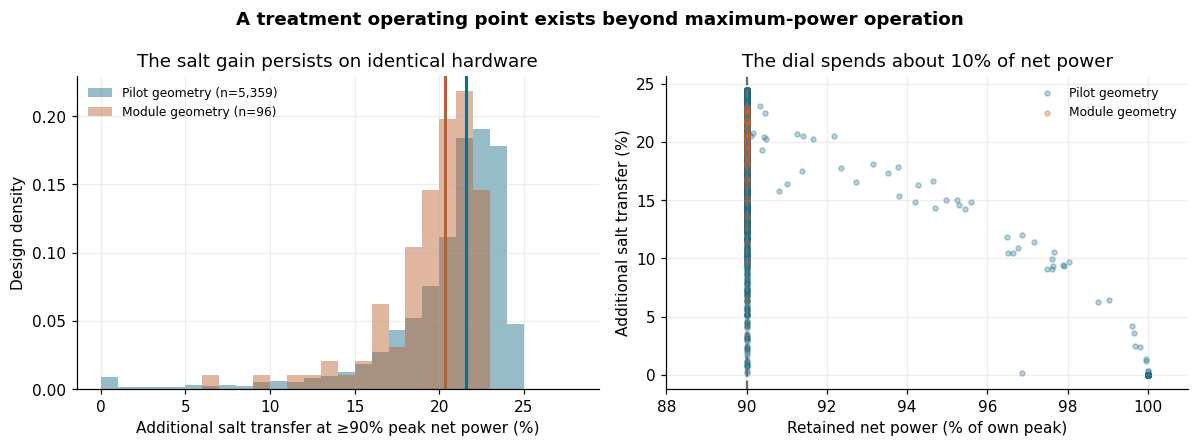

In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,4.1))
for data,label,color in [(paired,'Pilot geometry',COL['water']),(module_pairs,'Module geometry',COL['membrane'])]:
    x=data.salt_gain_pct.replace([np.inf,-np.inf],np.nan).dropna()
    ax[0].hist(x,bins=np.linspace(0,28,29),alpha=.45,density=True,label=f'{label} (n={len(x):,})',color=color)
    ax[0].axvline(x.median(),color=color,lw=2)
    ax[1].scatter(data.power_retained_pct,data.salt_gain_pct,s=11,alpha=.3,label=label,color=color)
ax[0].set(xlabel='Additional salt transfer at ≥90% peak net power (%)',ylabel='Design density',title='The salt gain persists on identical hardware')
ax[1].set(xlabel='Retained net power (% of own peak)',ylabel='Additional salt transfer (%)',title='The dial spends about 10% of net power')
ax[1].axvline(90,ls='--',color=COL['grey']);ax[1].set_xlim(88,101)
for a0 in ax:a0.legend(frameon=False,fontsize=8)
fig.suptitle('A treatment operating point exists beyond maximum-power operation',fontweight='bold');fig.tight_layout()
save(fig,1,'operating_dial','At fixed hardware, lowering load to a 90%-power floor increases modeled salt transfer.','master/screening_points; module/module_operating_points')

### Figure 2 — The power–salinity frontier shifts with dilute-water supply

The two panels use the same two flow ratios. The left zoom resolves the engineering difference; the right restores the feed and seawater references. The low-salinity inlet is 0.02 M ≈1.17 g/L, also shown in the right panel. “More salt” and “lower brine concentration” should not be treated as the same metric without accounting for membrane water transfer.

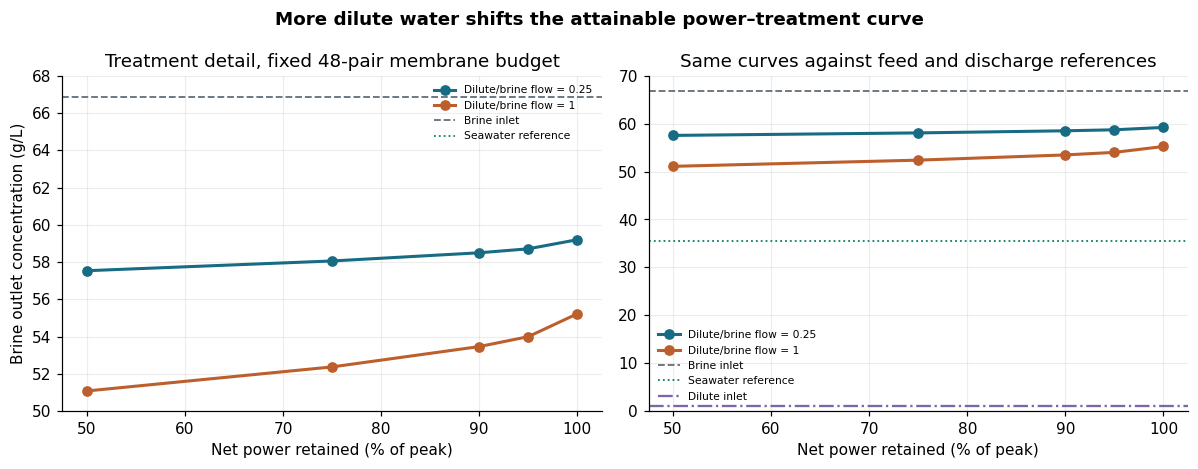

In [4]:
front=base[(base.N==48)&(base.phi.isin([.25,1.0]))].copy()
peak=front[front.objective=='peak'].set_index('phi').net_W
front['power_pct']=100*front.apply(lambda z:z.net_W/peak[z.phi],axis=1)
fig,ax=plt.subplots(1,2,figsize=(11,4.3),sharex=True)
for phi,color in [(0.25,COL['water']),(1.0,COL['membrane'])]:
    g=front[front.phi==phi].sort_values('power_pct')
    for a0 in ax:a0.plot(g.power_pct,g.ch_out_g_L,'o-',label=f'Dilute/brine flow = {phi:g}',color=color,lw=2)
feed=1.1435546261753167*58.44; ocean=35.5; dilute=.02*58.44
for a0 in ax:
    a0.axhline(feed,ls='--',color=COL['grey'],lw=1.2,label='Brine inlet')
    a0.axhline(ocean,ls=':',color=COL['salt'],lw=1.2,label='Seawater reference')
    a0.set_xlabel('Net power retained (% of peak)')
ax[1].axhline(dilute,ls='-.',color='#7b67a5',label='Dilute inlet')
ax[0].set(ylim=(50,68),ylabel='Brine outlet concentration (g/L)',title='Treatment detail, fixed 48-pair membrane budget')
ax[1].set(ylim=(0,70),title='Same curves against feed and discharge references')
ax[0].legend(fontsize=7,frameon=False);ax[1].legend(fontsize=7,frameon=False)
fig.suptitle('More dilute water shifts the attainable power–treatment curve',fontweight='bold');fig.tight_layout()
save(fig,2,'frontier_water_shift','Dilute supply shifts the frontier; load selects the operating point within it.','master/screening_points')

### Figure 3 — What physically changes the brine concentration?

For a single 48-pair stack, migrate and diffuse terms are converted to concentration-equivalent benefits at the **inlet brine flow**. The final term is the exactly reconstructed concentration penalty from the modeled change in brine flow. Thus migration + diffusion − water penalty equals the modeled inlet-to-outlet concentration drop; the water term is not “negative salt transfer.”

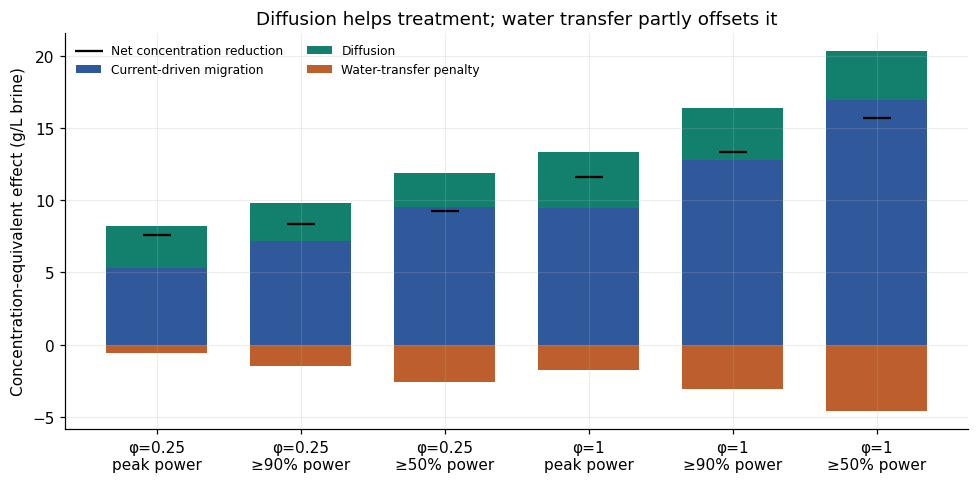

In [5]:
q_h=5e-6; molar_mass=58.44
rows=[]
for phi in [.25,1.0]:
 for objective in ['peak','salt_0.9','salt_0.5']:
    row=front[(front.phi==phi)&(front.objective==objective)].iloc[0]
    migration=row.migration_mol_s*molar_mass/(q_h*1000)
    diffusion=row.diffusion_mol_s*molar_mass/(q_h*1000)
    volume_neutral=feed-(row.salt_mol_s*molar_mass/(q_h*1000))
    penalty=row.ch_out_g_L-volume_neutral
    actual=feed-row.ch_out_g_L
    assert abs(migration+diffusion-penalty-actual)<1e-6
    rows.append({'phi':phi,'objective':objective,'migration':migration,'diffusion':diffusion,'water_penalty':penalty,'actual_benefit':actual})
mech=table(pd.DataFrame(rows),'mechanism_decomposition')
fig,ax=plt.subplots(figsize=(9,4.5));xx=np.arange(len(mech));w=.7
ax.bar(xx,mech.migration,width=w,color=COL['power'],label='Current-driven migration')
ax.bar(xx,mech.diffusion,bottom=mech.migration,width=w,color=COL['salt'],label='Diffusion')
ax.bar(xx,-mech.water_penalty,width=w,color=COL['membrane'],label='Water-transfer penalty')
ax.scatter(xx,mech.actual_benefit,color='black',marker='_',s=350,label='Net concentration reduction')
ax.set_xticks(xx,[f'φ={x.phi:g}\n'+('peak power' if x.objective=='peak' else f'≥{100*float(x.objective.split("_")[1]):g}% power') for x in mech.itertuples()])
ax.set(ylabel='Concentration-equivalent effect (g/L brine)',title='Diffusion helps treatment; water transfer partly offsets it')
ax.legend(ncol=2,fontsize=8,frameon=False);fig.tight_layout()
save(fig,3,'transport_mechanisms','Brine concentration reflects migration plus diffusion minus the water-transfer concentration penalty.','master/screening_points')

## B. The two scarce resources and the architecture decision

We do not compare stacks with different membrane or fresh-dilute supply when making an architecture claim. The broad resource map uses a **one-stage, independent circuit** at the 90%-power operating point; the architecture charts then hold the resources fixed.

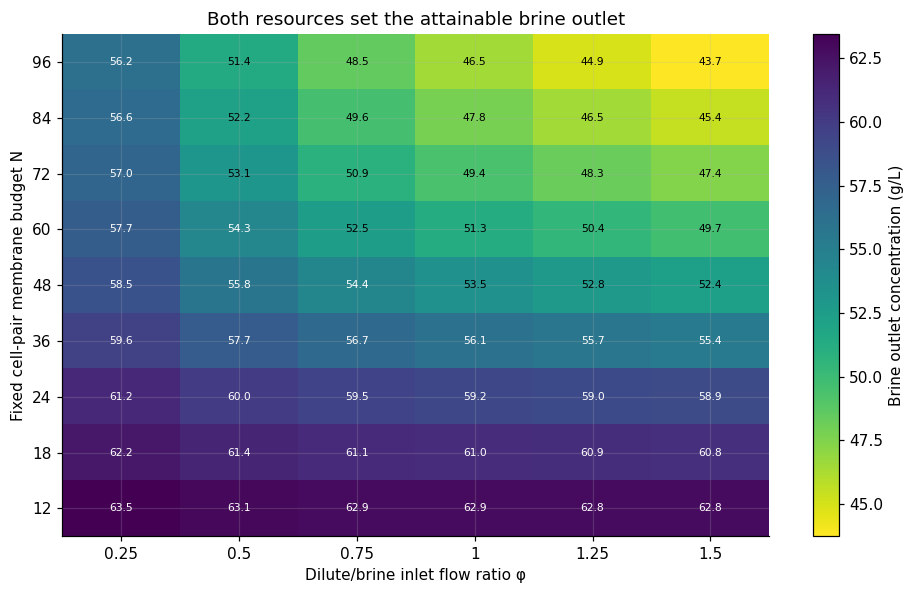

In [6]:
axis_N=[12,18,24,36,48,60,72,84,96];axis_phi=[.25,.5,.75,1,1.25,1.5]
resource=base[(base.objective=='salt_0.9')&(base.N.isin(axis_N))&(base.phi.isin(axis_phi))]
pivot=resource.pivot(index='N',columns='phi',values='ch_out_g_L').reindex(index=axis_N,columns=axis_phi)
assert pivot.notna().all().all(), 'Resource grid is incomplete'
fig,ax=plt.subplots(figsize=(8.8,5.5));im=ax.imshow(pivot.values,origin='lower',aspect='auto',cmap='viridis_r')
for i in range(len(axis_N)):
 for j in range(len(axis_phi)):ax.text(j,i,f'{pivot.iloc[i,j]:.1f}',ha='center',va='center',fontsize=7,color='white' if pivot.iloc[i,j]>54 else 'black')
ax.set_xticks(range(len(axis_phi)),[f'{v:g}' for v in axis_phi]);ax.set_yticks(range(len(axis_N)),axis_N)
ax.set(xlabel='Dilute/brine inlet flow ratio φ',ylabel='Fixed cell-pair membrane budget N',title='Both resources set the attainable brine outlet')
fig.colorbar(im,ax=ax,label='Brine outlet concentration (g/L)');fig.tight_layout()
save(fig,4,'resource_map','Brine treatment depends jointly on membrane pairs and available dilute flow.','master/screening_points')

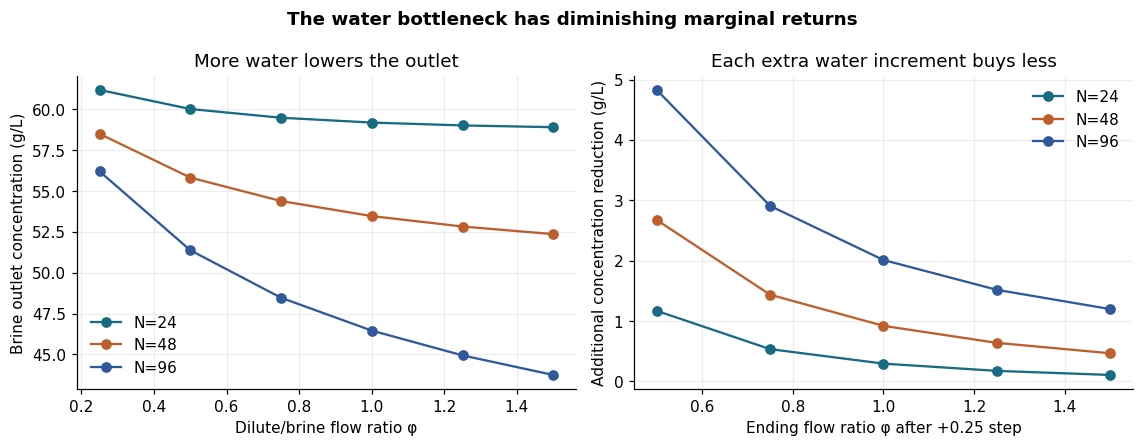

In [7]:
fig,ax=plt.subplots(1,2,figsize=(10.5,4.1))
for N,color in [(24,COL['water']),(48,COL['membrane']),(96,COL['power'])]:
 g=resource[resource.N==N].sort_values('phi')
 ax[0].plot(g.phi,g.ch_out_g_L,'o-',label=f'N={N}',color=color)
 step=-np.diff(g.ch_out_g_L.values)
 ax[1].plot(g.phi.values[1:],step,'o-',label=f'N={N}',color=color)
ax[0].set(xlabel='Dilute/brine flow ratio φ',ylabel='Brine outlet concentration (g/L)',title='More water lowers the outlet')
ax[1].set(xlabel='Ending flow ratio φ after +0.25 step',ylabel='Additional concentration reduction (g/L)',title='Each extra water increment buys less')
for a0 in ax:a0.legend(frameon=False)
fig.suptitle('The water bottleneck has diminishing marginal returns',fontweight='bold');fig.tight_layout()
save(fig,5,'dilute_marginal_returns','Dilute supply is valuable but its marginal treatment return falls with φ.','master/screening_points')

### Figures 6–8 — What rearranging fixed resources can and cannot do

A configuration span is the maximum minus minimum *within one N, φ, and operating objective*. It is not the gain available from a recommended layout. The doubling comparison uses the same one-stage independent circuit at N=24 and N=48. Unequal allocation is evaluated only where an equal allocation was also tested for the same design group.

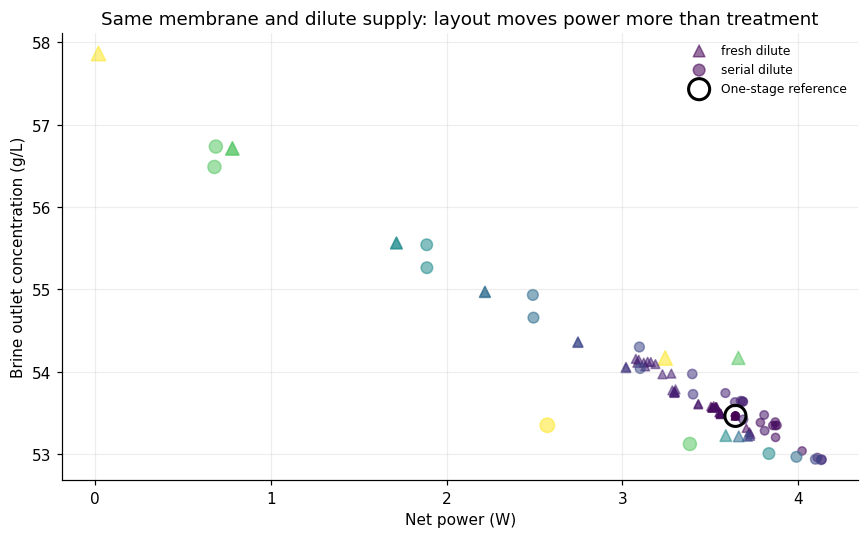

In [8]:
config=pd.read_parquet(RUN/'master/configuration_matched_spreads.parquet')
sc=s[(s.N==48)&(s.phi==1.0)&(s.objective=='salt_0.9')].copy()
fig,ax=plt.subplots(figsize=(8,5));markers={'serial':'o','fresh':'^'}
for route,g in sc.groupby('route'):
 ax.scatter(g.net_W,g.ch_out_g_L,c=g.S,cmap='viridis',s=25+g.S*2,alpha=.55,marker=markers[route],label=f'{route} dilute')
ref=base[(base.N==48)&(base.phi==1)&(base.objective=='salt_0.9')].iloc[0]
ax.scatter([ref.net_W],[ref.ch_out_g_L],s=190,facecolors='none',edgecolors='black',lw=2,label='One-stage reference')
ax.set(xlabel='Net power (W)',ylabel='Brine outlet concentration (g/L)',title='Same membrane and dilute supply: layout moves power more than treatment')
ax.legend(frameon=False,fontsize=8);fig.tight_layout()
save(fig,6,'configuration_cloud','Architecture changes net power substantially while brine outlet occupies a narrower band at fixed resources.','master/screening_points')

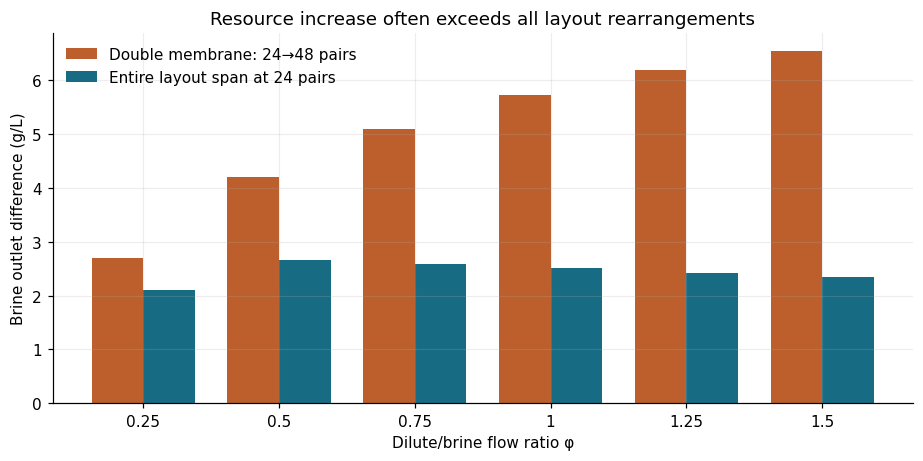

In [9]:
cs=config[(config.N==24)&(config.objective=='salt_0.9')].set_index('phi')
one=resource[resource.N.isin([24,48])].pivot(index='phi',columns='N',values='ch_out_g_L')
double=one[24]-one[48]
span=cs.brine_out_span_g_L.reindex(axis_phi)
assert double.notna().all() and span.notna().all()
fig,ax=plt.subplots(figsize=(8.5,4.3));x=np.arange(len(axis_phi));w=.38
ax.bar(x-w/2,double.values,w,label='Double membrane: 24→48 pairs',color=COL['membrane'])
ax.bar(x+w/2,span.values,w,label='Entire layout span at 24 pairs',color=COL['water'])
ax.set_xticks(x,[f'{v:g}' for v in axis_phi]);ax.set(xlabel='Dilute/brine flow ratio φ',ylabel='Brine outlet difference (g/L)',title='Resource increase often exceeds all layout rearrangements')
ax.legend(frameon=False);fig.tight_layout()
save(fig,7,'membrane_vs_layout','A defined membrane increase often changes treatment more than the full architecture span at fixed resources.','master/screening_points; master/configuration_matched_spreads')

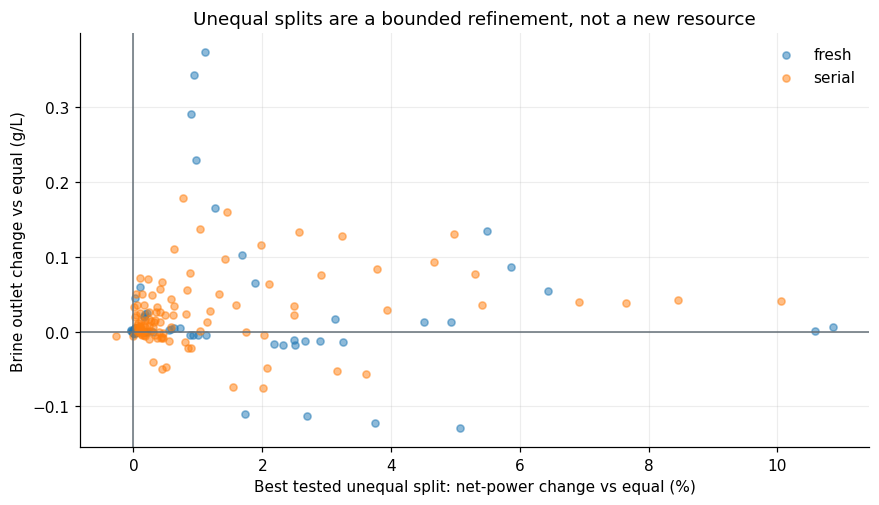

In [10]:
alloc=s[(s.S>1)&(s.objective=='peak')&(s.circuit=='independent_stacks')].copy()
alloc['equal']=alloc.allocation.map(lambda a:max(a)-min(a)<=1)
group=['N','phi','S','route','circuit']
rows=[]
for key,g in alloc.groupby(group):
 eq=g[g.equal];uneq=g[~g.equal]
 if eq.empty or uneq.empty:continue
 e=eq.loc[eq.net_W.idxmax()];u=uneq.loc[uneq.net_W.idxmax()]
 rows.append(dict(zip(group,key))|{'net_gain_pct':100*(u.net_W/e.net_W-1),'outlet_change_g_L':u.ch_out_g_L-e.ch_out_g_L})
allocation=table(pd.DataFrame(rows),'unequal_allocation_matched')
fig,ax=plt.subplots(figsize=(8.1,4.7))
for route,g in allocation.groupby('route'):
 ax.scatter(g.net_gain_pct,g.outlet_change_g_L,s=22,alpha=.5,label=route)
ax.axvline(0,color=COL['grey'],lw=1);ax.axhline(0,color=COL['grey'],lw=1)
ax.set(xlabel='Best tested unequal split: net-power change vs equal (%)',ylabel='Brine outlet change vs equal (g/L)',title='Unequal splits are a bounded refinement, not a new resource')
ax.legend(frameon=False);fig.tight_layout()
save(fig,8,'unequal_allocation','Unequal allocation is evaluated against the equal split at identical N, φ, stages, route, and circuit.','master/screening_points')

## C. Scale, routing, and pumping

The pilot-to-module comparison below matches membrane area per brine flow within about 4% (24 pilot pairs at 0.05 m²/sheet versus one 200-pair module at 0.10 m²/sheet). Geometry and pumping differ, so **absolute power is not expected to be invariant**. Figure 10 compares fresh and serial routing at the *same absolute net power*, not each route's own peak.

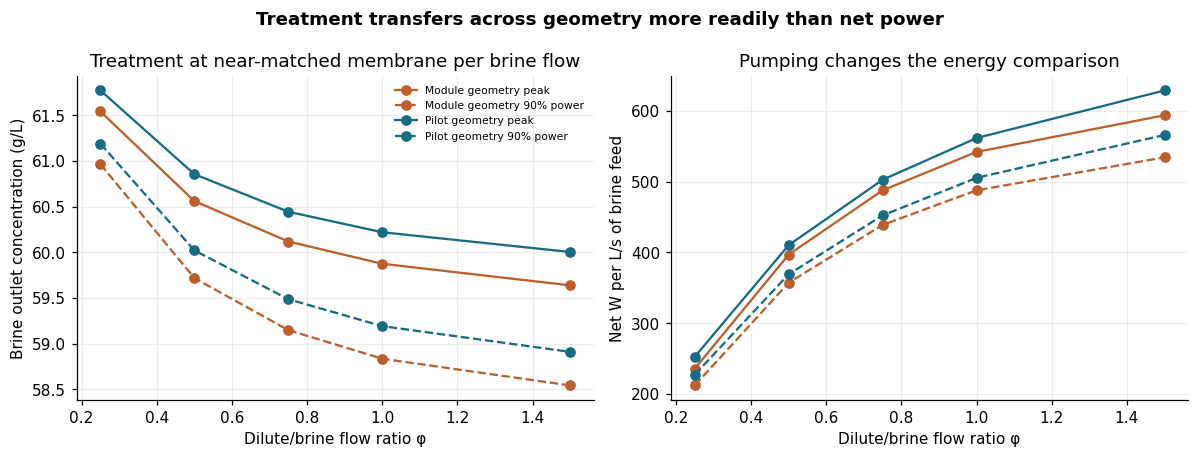

In [11]:
pilot=base[(base.N==24)&(base.objective.isin(['peak','salt_0.9']))&(base.phi.isin([.25,.5,.75,1,1.5]))].copy()
pilot['scale']='Pilot geometry';pilot['specific_power']=pilot.net_W/(5e-6*1000)
commercial=mod[(mod.N==200)&(mod.stages==1)&(mod.wiring=='serial')&(mod.circuit=='independent_stacks')&(mod.objective.isin(['peak','salt_0.9']))&(mod.phi.isin([.25,.5,.75,1,1.5]))].copy()
commercial['scale']='Module geometry';commercial['specific_power']=commercial.net_W/(commercial.qh_in_m3_s*1000)
scale_data=table(pd.concat([pilot[['scale','phi','objective','specific_power','ch_out_g_L']],commercial[['scale','phi','objective','specific_power','ch_out_g_L']]],ignore_index=True),'scale_resource_matched')
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
for (scale,obj),g in scale_data.groupby(['scale','objective']):
 color=COL['water'] if scale=='Pilot geometry' else COL['membrane'];ls='-' if obj=='peak' else '--'
 g=g.sort_values('phi');label=scale+(' peak' if obj=='peak' else ' 90% power')
 ax[0].plot(g.phi,g.ch_out_g_L,'o',ls=ls,color=color,label=label)
 ax[1].plot(g.phi,g.specific_power,'o',ls=ls,color=color,label=label)
ax[0].set(xlabel='Dilute/brine flow ratio φ',ylabel='Brine outlet concentration (g/L)',title='Treatment at near-matched membrane per brine flow')
ax[1].set(xlabel='Dilute/brine flow ratio φ',ylabel='Net W per L/s of brine feed',title='Pumping changes the energy comparison')
ax[0].legend(fontsize=7,frameon=False);fig.suptitle('Treatment transfers across geometry more readily than net power',fontweight='bold');fig.tight_layout()
save(fig,9,'pilot_module_bridge','At near-matched membrane per brine flow, compare treatment and specific net power separately.','master/screening_points; module/module_operating_points')

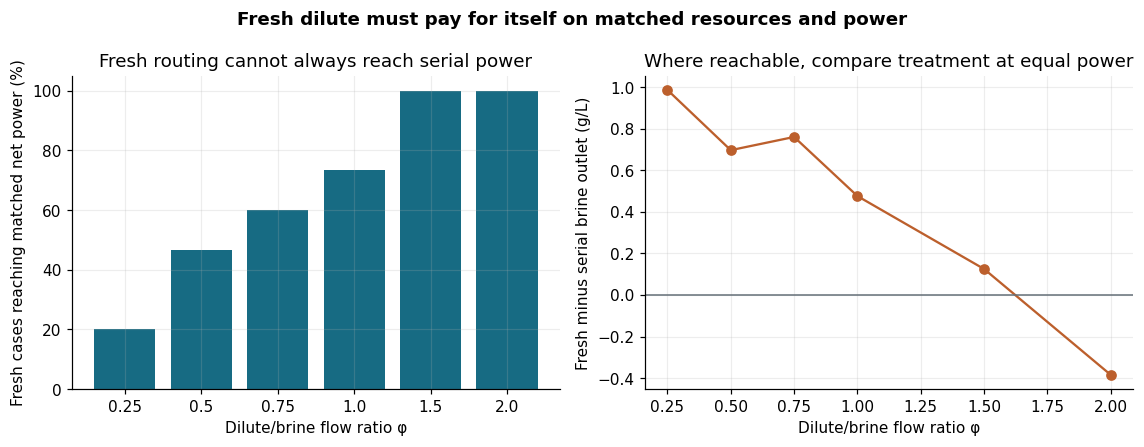

In [12]:
matched=pd.read_parquet(RUN/'module/module_matched_power.parquet')
fm=matched[(matched.variant=='common_voltage_bulk')&(matched.circuit=='independent_stacks')&(matched.stages==2)&(matched.N==400)&(matched.wiring=='fresh')].copy()
reach=fm.groupby('phi').reachable.mean().sort_index()
penalty=fm[fm.reachable].groupby('phi').delta_ch_out_vs_reference_g_L.median().sort_index()
fig,ax=plt.subplots(1,2,figsize=(10.5,4.1))
ax[0].bar(reach.index.astype(str),reach.values*100,color=COL['water']);ax[0].set(ylim=(0,105),xlabel='Dilute/brine flow ratio φ',ylabel='Fresh cases reaching matched net power (%)',title='Fresh routing cannot always reach serial power')
ax[1].plot(penalty.index,penalty.values,'o-',color=COL['membrane']);ax[1].axhline(0,color=COL['grey'],lw=1)
ax[1].set(xlabel='Dilute/brine flow ratio φ',ylabel='Fresh minus serial brine outlet (g/L)',title='Where reachable, compare treatment at equal power')
fig.suptitle('Fresh dilute must pay for itself on matched resources and power',fontweight='bold');fig.tight_layout()
save(fig,10,'fresh_matched_power','Fresh routing is judged only at matched membrane, water, module count, and absolute net power.','module/module_matched_power')

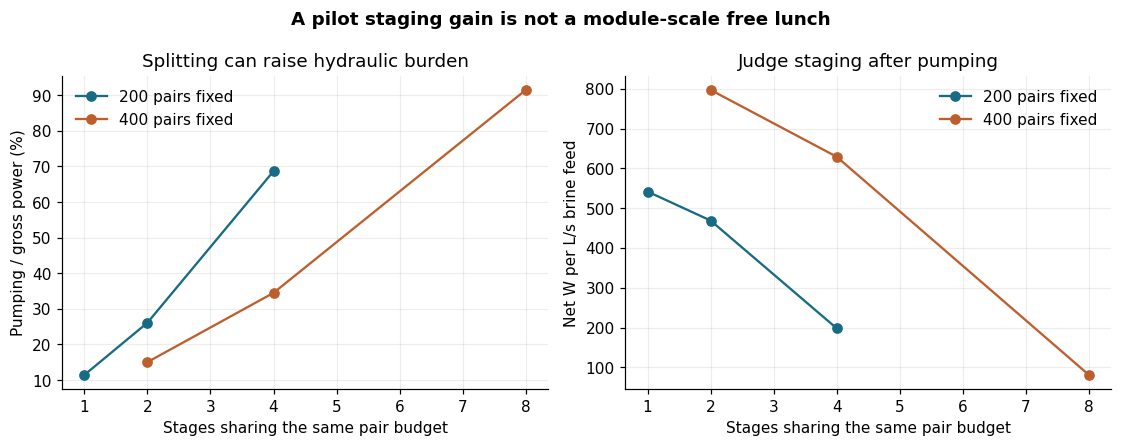

In [13]:
nom=mod[(mod.objective=='peak')&(mod.wiring=='serial')&(mod.circuit=='independent_stacks')&(mod.phi==1)&(mod.N.isin([200,400]))].copy()
nom['pump_share']=100*nom.pump_W/nom.gross_W
nom['specific_net']=nom.net_W/(nom.qh_in_m3_s*1000)
nom=nom.groupby(['N','stages'],as_index=False)[['pump_share','specific_net']].median()
fig,ax=plt.subplots(1,2,figsize=(10.3,4.1))
for N,g in nom.groupby('N'):
 color=COL['water'] if N==200 else COL['membrane'];g=g.sort_values('stages')
 ax[0].plot(g.stages,g.pump_share,'o-',label=f'{N} pairs fixed',color=color)
 ax[1].plot(g.stages,g.specific_net,'o-',label=f'{N} pairs fixed',color=color)
ax[0].set(xlabel='Stages sharing the same pair budget',ylabel='Pumping / gross power (%)',title='Splitting can raise hydraulic burden')
ax[1].set(xlabel='Stages sharing the same pair budget',ylabel='Net W per L/s brine feed',title='Judge staging after pumping')
for a0 in ax:a0.legend(frameon=False)
fig.suptitle('A pilot staging gain is not a module-scale free lunch',fontweight='bold');fig.tight_layout()
save(fig,11,'module_staging_hydraulics','At fixed module pair budget, staging must be evaluated after pumping.','module/module_operating_points')

## D. Fouling and parameter sensitivity

These are **scenario** calculations, not inferred plant fouling rates. Figure 12 compares every severity with its clean twin. Figures 13–14 isolate spatial location and the MTFC/Genius concentration–divalent resistance proxy. For the latter, the “divalent fraction” is an input proxy: no Ca/Mg/SO₄ species balances or scaling chemistry are solved.

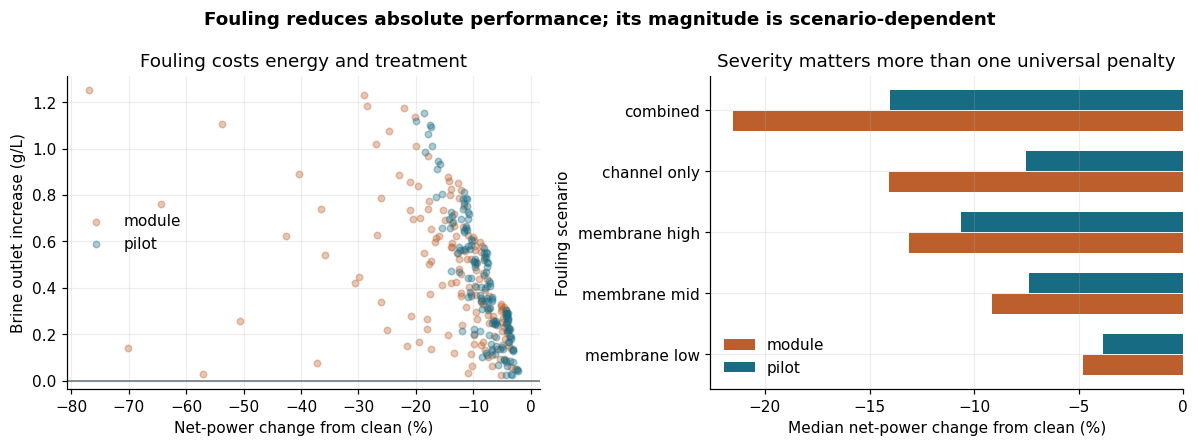

In [14]:
foul={name:pd.read_parquet(RUN/name/'fouling_paired.parquet') for name in ['fouling_matrix','spatial_fouling','mtfc_fouling']}
f=foul['fouling_matrix'];fp=f[(f.objective=='peak')&(f.severity!='clean')].copy();fp['outlet_penalty']=fp.ch_out_g_L-fp.clean_ch_out_g_L
fig,ax=plt.subplots(1,2,figsize=(11,4.1))
for scale,g in fp.groupby('scale'):
 col=COL['water'] if scale=='pilot' else COL['membrane']
 ax[0].scatter(g.net_change_pct,g.outlet_penalty,s=18,alpha=.35,label=scale,color=col)
severity_order=['membrane_low','membrane_mid','membrane_high','channel_only','combined']
for k,(scale,g) in enumerate(fp.groupby('scale')):
 med=g.groupby('severity').net_change_pct.median().reindex(severity_order)
 ypos=np.arange(len(severity_order))+(k-.5)*.34
 ax[1].barh(ypos,med.values,height=.33,label=scale,color=COL['water'] if scale=='pilot' else COL['membrane'])
ax[1].set_yticks(range(len(severity_order)),[x.replace('_',' ') for x in severity_order])
ax[0].axhline(0,color=COL['grey'],lw=1);ax[0].set(xlabel='Net-power change from clean (%)',ylabel='Brine outlet increase (g/L)',title='Fouling costs energy and treatment')
ax[1].set(xlabel='Median net-power change from clean (%)',ylabel='Fouling scenario',title='Severity matters more than one universal penalty')
for a0 in ax:a0.legend(frameon=False)
fig.suptitle('Fouling reduces absolute performance; its magnitude is scenario-dependent',fontweight='bold');fig.tight_layout()
save(fig,12,'fouling_matrix','Fouling scenario changes both net power and brine outlet against the same clean design.','fouling_matrix/fouling_paired')

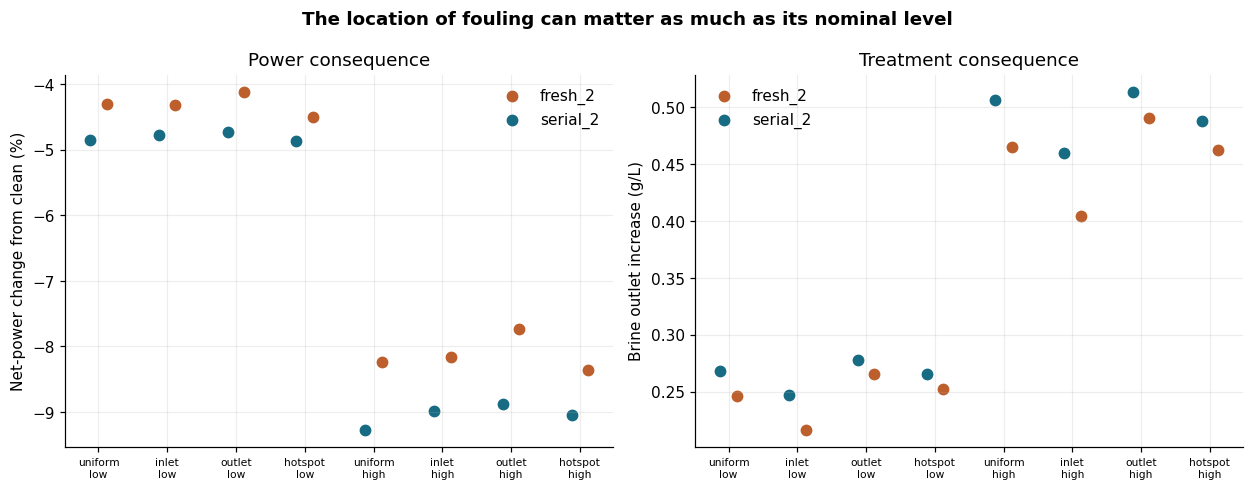

In [15]:
sp=foul['spatial_fouling'];sp=sp[(sp.scale=='module')&(sp.phi==1)&(sp.objective=='peak')&(sp.design.isin(['serial_2','fresh_2']))&(sp.severity!='clean')].copy()
sp['outlet_penalty']=sp.ch_out_g_L-sp.clean_ch_out_g_L
order=['uniform_low','inlet_low','outlet_low','hotspot_low','uniform_high','inlet_high','outlet_high','hotspot_high']
fig,ax=plt.subplots(1,2,figsize=(11.5,4.5),sharex=True)
for design,g in sp.groupby('design'):
 color=COL['water'] if design=='serial_2' else COL['membrane'];g=g.set_index('severity').reindex(order)
 offset=-.12 if design=='serial_2' else .12
 ax[0].scatter(np.arange(len(order))+offset,g.net_change_pct,label=design,color=color,s=45)
 ax[1].scatter(np.arange(len(order))+offset,g.outlet_penalty,label=design,color=color,s=45)
for a0 in ax:a0.set_xticks(range(len(order)),[x.replace('_','\n') for x in order],fontsize=7);a0.legend(frameon=False)
ax[0].set(ylabel='Net-power change from clean (%)',title='Power consequence')
ax[1].set(ylabel='Brine outlet increase (g/L)',title='Treatment consequence')
fig.suptitle('The location of fouling can matter as much as its nominal level',fontweight='bold');fig.tight_layout()
save(fig,13,'spatial_fouling','Spatial fouling location changes performance under equal scenario severity.','spatial_fouling/fouling_paired')

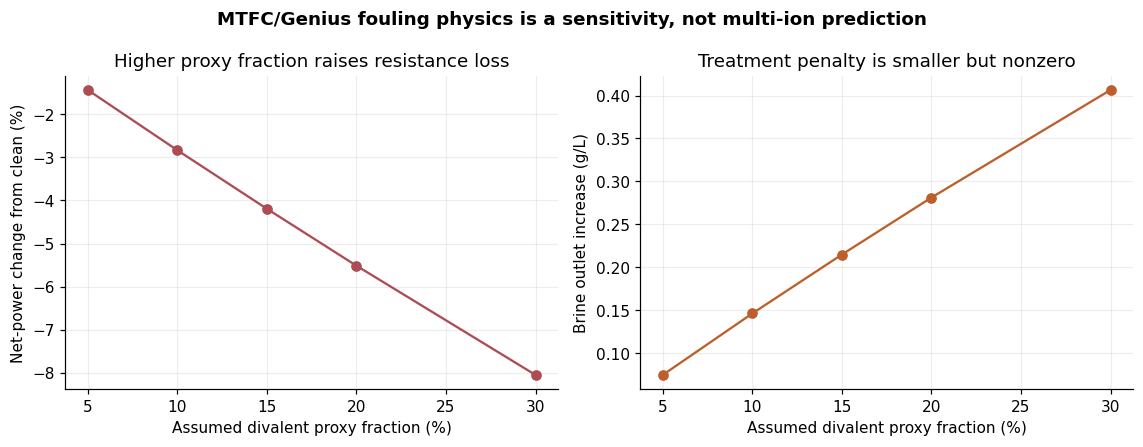

In [16]:
mt=foul['mtfc_fouling'];mt=mt[(mt.scale=='module')&(mt.design=='single')&(mt.objective=='peak')&(mt.severity.str.startswith('cdf_'))].copy()
mt['fraction']=mt.severity.str.replace('cdf_','').astype(float)/100
mt['outlet_penalty']=mt.ch_out_g_L-mt.clean_ch_out_g_L
mm=mt.groupby('fraction')[['net_change_pct','outlet_penalty']].median().sort_index()
fig,ax=plt.subplots(1,2,figsize=(10.5,4.1))
ax[0].plot(mm.index*100,mm.net_change_pct,'o-',color=COL['fouling']);ax[0].set(xlabel='Assumed divalent proxy fraction (%)',ylabel='Net-power change from clean (%)',title='Higher proxy fraction raises resistance loss')
ax[1].plot(mm.index*100,mm.outlet_penalty,'o-',color=COL['membrane']);ax[1].set(xlabel='Assumed divalent proxy fraction (%)',ylabel='Brine outlet increase (g/L)',title='Treatment penalty is smaller but nonzero')
fig.suptitle('MTFC/Genius fouling physics is a sensitivity, not multi-ion prediction',fontweight='bold');fig.tight_layout()
save(fig,14,'mtfc_divalent_proxy','The legacy concentration–divalent resistance proxy shifts outcomes, without predicting multi-ion transport.','mtfc_fouling/fouling_paired')

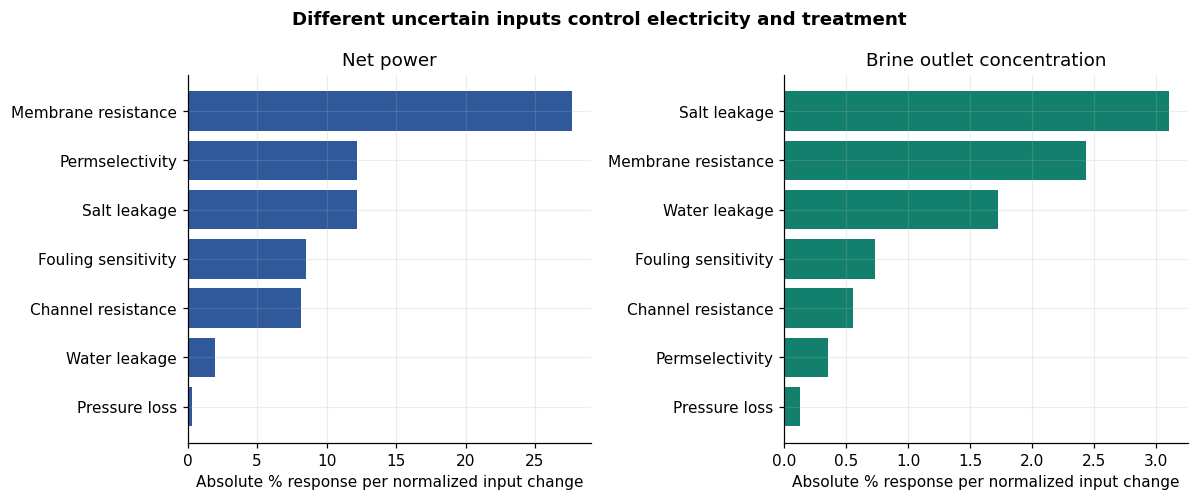

In [17]:
mr=pd.read_parquet(RUN/'morris_v2/morris_ranking.parquet')
fig,ax=plt.subplots(1,2,figsize=(11,4.6))
labelmap={'membrane_ASR_multiplier':'Membrane resistance','solution_shadow_multiplier':'Channel resistance','channel_pressure_multiplier':'Pressure loss','permselectivity':'Permselectivity','salt_permeance_multiplier':'Salt leakage','water_permeance_multiplier':'Water leakage','fouling_beta':'Fouling sensitivity'}
for a0,metric,title in zip(ax,['net_W','ch_out_g_L'],['Net power','Brine outlet concentration']):
 g=mr[(mr.design=='single')&(mr.objective=='peak')&(mr.metric==metric)].sort_values('mu_star')
 a0.barh(g.param.map(labelmap),g.mu_star,color=COL['power'] if metric=='net_W' else COL['salt'])
 a0.set(xlabel='Absolute % response per normalized input change',title=title)
fig.suptitle('Different uncertain inputs control electricity and treatment',fontweight='bold');fig.tight_layout()
save(fig,15,'morris_rankings','Power and treatment have different parameter sensitivities; this Morris screen is shallow and conditional.','morris_v2/morris_ranking')

## E. Economics and model credibility

The Monte Carlo reuses **4,000 paired cost draws** over the already calculated 40-section design library. It does not resample physical transport or include a Carlsbad cost quote. `coverage_complete=False` and `numerical_grade=screen` are retained in the exported evidence. To make a policy comparison fair, the two policies are paired on the same baseline, duty, outlet treatment, dilute ratio, and capital budget. Missing pairs are excluded, never imputed.

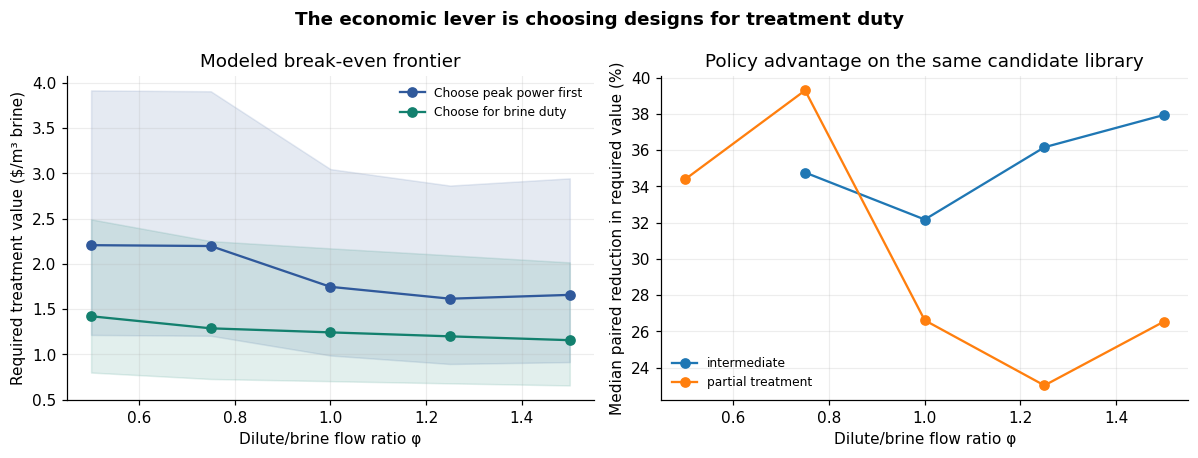

In [18]:
tea=pd.read_parquet(RUN/'master/tea_summary.parquet')
assert len(pd.read_parquet(RUN/'master/tea_draws.parquet'))==4000
assert tea.coverage_complete.eq(False).all()
t=tea[tea.required_value_median.notna()].copy();t['budget_key']=t.capital_budget_USD.fillna(-1)
keys=['baseline','duty','outlet_mode','phi','budget_key']
tp=t.pivot_table(index=keys,columns='policy',values='required_value_median',aggfunc='first').dropna().reset_index()
tp['saving_pct']=100*(1-tp.treatment_aware/tp.power_first)
table(tp,'tea_matched_policy_pairs')
focus=tp[(tp.baseline=='existing_dilute_service')&(tp.outlet_mode=='pooled')&(tp.budget_key==-1)&(tp.duty=='partial_treatment')].sort_values('phi')
focus_bands=t[(t.baseline=='existing_dilute_service')&(t.outlet_mode=='pooled')&(t.budget_key==-1)&(t.duty=='partial_treatment')].copy()
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(focus.phi,focus.power_first,'o-',color=COL['power'],label='Choose peak power first')
ax[0].plot(focus.phi,focus.treatment_aware,'o-',color=COL['salt'],label='Choose for brine duty')
for policy,color in [('power_first',COL['power']),('treatment_aware',COL['salt'])]:
 g=focus_bands[focus_bands.policy==policy].sort_values('phi')
 ax[0].fill_between(g.phi,g.required_value_p05,g.required_value_p95,color=color,alpha=.12)
ax[0].set(xlabel='Dilute/brine flow ratio φ',ylabel='Required treatment value ($/m³ brine)',title='Modeled break-even frontier')
ax[0].legend(frameon=False,fontsize=8)
for duty,g in tp.groupby('duty'):
 h=g.groupby('phi').saving_pct.median().sort_index();ax[1].plot(h.index,h.values,'o-',label=duty.replace('_',' '))
ax[1].set(xlabel='Dilute/brine flow ratio φ',ylabel='Median paired reduction in required value (%)',title='Policy advantage on the same candidate library')
ax[1].legend(frameon=False,fontsize=8)
fig.suptitle('The economic lever is choosing designs for treatment duty',fontweight='bold');fig.tight_layout()
save(fig,16,'screening_tea_frontier','Treatment-aware selection lowers modeled required service value in paired 40-section screening cases.','master/tea_summary; master/tea_draws')

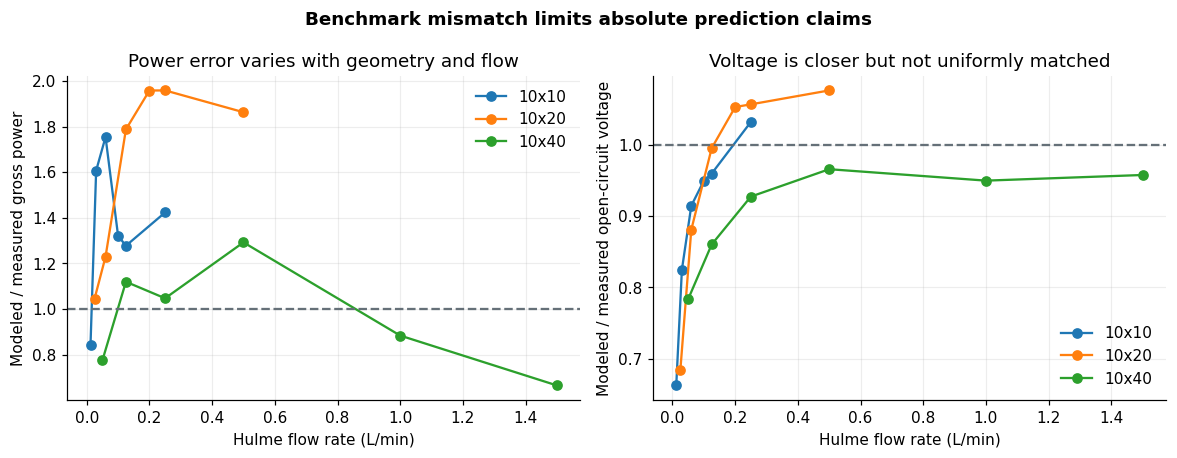

In [19]:
bench=pd.read_parquet(RUN/'master/benchmark_comparison.parquet')
bench=bench[(bench.source=='0.51M')&(bench.variant=='common_voltage_bulk')].copy()
fig,ax=plt.subplots(1,2,figsize=(10.8,4.2),sharex=True)
for stack,g in bench.groupby('stack'):
 g=g.sort_values('flow_Lmin')
 ax[0].plot(g.flow_Lmin,g.power_ratio,'o-',label=stack)
 ax[1].plot(g.flow_Lmin,g.ocv_ratio,'o-',label=stack)
for a0 in ax:a0.axhline(1,color=COL['grey'],ls='--');a0.set_xlabel('Hulme flow rate (L/min)');a0.legend(frameon=False)
ax[0].set(ylabel='Modeled / measured gross power',title='Power error varies with geometry and flow')
ax[1].set(ylabel='Modeled / measured open-circuit voltage',title='Voltage is closer but not uniformly matched')
fig.suptitle('Benchmark mismatch limits absolute prediction claims',fontweight='bold');fig.tight_layout()
save(fig,17,'benchmark_mismatch','The unfitted Hulme comparison shows structured power mismatch; operating ratios remain model-conditional.','master/benchmark_comparison')

## F. Claim ledger and handoff

The ledger below makes a manuscript decision rather than declaring every figure equally publishable. “Lead” identifies the most coherent quantitative claim. “Supporting” claims explain why it matters for design. “Boundary” rows state where the present evidence stops. The analysis does **not** infer field performance from scenario fouling or from the 40-section cost screen.

In [20]:
def med(x):return float(np.nanmedian(x))
master_gain=med(paired.salt_gain_pct);module_gain=med(module_pairs.salt_gain_pct)
fouled=[]
for name,d in foul.items():
 q=d.pivot_table(index=['scale','phi','design','severity'],columns='objective',values='salt_mol_s',aggfunc='first').dropna()
 q=q[q.index.get_level_values('severity')!='clean']
 fouled.extend((100*(q['salt_0.9']/q['peak']-1)).tolist())
config_median=float(config[(config.objective=='salt_0.9') & config.N.isin(axis_N)].brine_out_span_g_L.median())
double_median=float(double.median())
policy_saving=med(tp.saving_pct)
claims=[
 {'grade':'LEAD — model-conditional','claim':'An electrical operating point retains ~90% of peak net power while increasing salt transfer on identical hardware.',
  'number':f'Median additional salt: pilot {master_gain:.1f}%; module {module_gain:.1f}%; fouled scenario median {med(fouled):.1f}%.',
  'evidence':'F01–F03, F12–F14; paired peak vs salt_0.9','next_test':'Targeted fine mesh and resistance-bracket confirmation of the retained-power curve.'},
 {'grade':'SUPPORTING — fixed resource','claim':'Membrane addition and layout can both change outlet salinity; compare them only within the same fixed-budget cell.',
  'number':f'Median main-grid whole-layout brine-out span {config_median:.2f} g/L (54 matched cells); median 24→48-pair improvement {double_median:.2f} g/L across six φ.',
  'evidence':'F04–F08; main grid N and φ only. The pooled 0.44 g/L figure is retired.','next_test':'Check with a site-feasible flow and module count.'},
 {'grade':'SUPPORTING — screening economics','claim':'Choosing for brine duty reduces modeled treatment break-even value relative to choosing peak power first.',
  'number':f'Median paired saving {policy_saving:.1f}% across {len(tp)} matched screening rows; 4,000 paired cost draws.',
  'evidence':'F16; screening-grade candidate library','next_test':'Fine-mesh selected designs, complete candidate coverage, and site-specific costs.'},
 {'grade':'BOUNDARY','claim':'Absolute power and plant fouling predictions are not validated by this package.',
  'number':'Hulme power ratio varies by flow and stack; no measured fouling rates or multi-ion balances.',
  'evidence':'F12–F15, F17; benchmark and scenario inputs','next_test':'Bench I–V/flow calibration and measured brine/fouling data.'}
]
ledger=table(pd.DataFrame(claims),'claim_ledger')
table(pd.DataFrame(FIGURES),'figure_index')
readme="# OsmoFlux 40-section discovery package\n\nRun `OsmoFlux_analysis.ipynb` with the blueleaflabs kernel. It verifies the pinned parquets and writes 17 figures (PNG and SVG), evidence tables, and this ledger. No RED physics or Monte Carlo is rerun.\n\n## Paper spine\n\n"
readme+='\n'.join(f"- **{c['grade']}** {c['claim']} {c['number']} Evidence: {c['evidence']}." for c in claims)
readme+='\n\n## Interpretation guardrails\n\nThe current run is a complete 40-section screen, not a fine-mesh or experimental validation. Benchmark gross-power error remains structured by geometry and flow. Fouling severity and divalent fraction are scenario inputs, not site estimates. Cost values are screening-grade required treatment values; site costs and candidate coverage are incomplete. Do not call them measured tariffs or a validated global optimum.\n'
(OUT/'README.md').write_text(readme)
print(ledger.to_string(index=False))
print(f'Wrote {len(FIGURES)} figures, paired tables, claim ledger, README and manifest to {OUT}')

                           grade                                                                                                              claim                                                                                                                         number                                                                evidence                                                                           next_test
        LEAD — model-conditional An electrical operating point retains ~90% of peak net power while increasing salt transfer on identical hardware.                                               Median additional salt: pilot 21.6%; module 20.3%; fouled scenario median 21.1%.                               F01–F03, F12–F14; paired peak vs salt_0.9 Targeted fine mesh and resistance-bracket confirmation of the retained-power curve.
     SUPPORTING — fixed resource Membrane addition and layout can both change outlet salinity; compare them only within the same fixed-bud

## G. Final submission run: numerical audit and claim reconciliation

Sections A–F above reproduce the **historical 40-section screening package**. This
section reads the completed final submission run, including its 160/320/640-section
checks and fine-grade Monte Carlo TEA. It never modifies the run or its receipts.
Run this section to regenerate the audit tables and figures under
`analysis/final_submission_20261004_02/`. All paper numbers should be sourced from
this section or earlier sections explicitly marked historical. The benchmark remains
unfitted and does not establish experimental validation.


In [21]:
from pathlib import Path
import hashlib, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FINAL_PROJECT = Path(os.environ.get('OSMOFLUX_ROOT', '/Users/Shared/blueleaflabs/osmoflux')).resolve()
FINAL_RUN = FINAL_PROJECT/'runs_dev/REPRODUCIBILITY_E2E/final_submission_20261004_02'
FINAL_OUT = Path(os.environ.get('OSMOFLUX_FINAL_ANALYSIS_OUTPUT', str(FINAL_PROJECT/'analysis/final_submission_20261004_02'))).resolve()
FINAL_OUT.mkdir(parents=True, exist_ok=True)
FINAL_STATUS = json.loads((FINAL_RUN/'PIPELINE_STATUS.json').read_text())
assert FINAL_STATUS['status'].startswith('COMPUTATION_COMPLETE'), FINAL_STATUS['status']
assert not (FINAL_RUN/'PIPELINE_RUNNING.lock').exists(), 'Wait for the run to finish'
CATALOG = pd.read_csv(FINAL_RUN/'ANALYSIS/DATASET_CATALOG.csv')
REQUIRED_FINAL = ['master/screening_points.parquet','master/fine_operating_points.parquet',
                  'master/configuration_matched_spreads.parquet','master/benchmark_comparison.parquet',
                  'master/tea_summary.parquet','master/tea_draws.parquet',
                  'module/module_operating_points.parquet','five_factor_law/five_factor_rows.parquet']
def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''): h.update(block)
    return h.hexdigest()
for rel in REQUIRED_FINAL:
    recorded=CATALOG.loc[CATALOG.path.eq(rel),'sha256']
    assert len(recorded)==1 and sha256(FINAL_RUN/rel)==recorded.iloc[0],f'Input changed: {rel}'
(FINAL_OUT/'INPUT_MANIFEST.json').write_text(json.dumps({
    'run_root':str(FINAL_RUN),'pipeline_status':FINAL_STATUS['status'],
    'input_sha256':{rel:sha256(FINAL_RUN/rel) for rel in REQUIRED_FINAL},
    'source_notebook':str(FINAL_PROJECT/'OsmoFlux_analysis.ipynb')},indent=2)+'\n')
def export_final(df,name):
    df.to_csv(FINAL_OUT/f'{name}.csv',index=False)
    return df
print(f'Final run: {FINAL_RUN.name}; source parquets verified; output: {FINAL_OUT}')


Final run: final_submission_20261004_02; source parquets verified; output: /Users/Shared/blueleaflabs/osmoflux/analysis/final_submission_20261004_02


### G1. What caused the numerical flags?

A failed *fine* flag can mean mesh drift, failed optimization, or no valid model
points. Those causes are not interchangeable. The next cell reads every saved
fine-job receipt and its own 160/320/640-section results. It leaves the original
run untouched and writes `fine_flag_audit.csv` and `module_flow_budget_audit.csv`.


In [22]:
fine_rows=[]; flow_rows=[]
module_cfg=json.loads((FINAL_RUN/'module/CONFIG.json').read_text())
qh_module=float(module_cfg['physics']['q_h_m3_s'])
for study in ('master','module'):
    for result_path in sorted((FINAL_RUN/study/'jobs').glob('*/result.json')):
        result=json.loads(result_path.read_text())
        if 'all_points_pass' not in result: continue
        if result['all_points_pass']: continue
        levels=result.get('levels',[])
        failed=[x['objective'] for x in result.get('checks',[]) if not x.get('passed')]
        spec=result['spec'];label=result.get('label')
        if not failed: failed=['NO_VALID_FINE_POINTS']
        for objective in failed:
            row={'study':study,'job_id':result_path.parent.name,'label':label,
                 'objective':objective,'N':spec['N'],'phi':spec['phi'],
                 'stages':len(spec['na']),'wiring':spec['wiring'],
                 'optimizer_terminated':None,'mesh_320_net_W':None,'mesh_640_net_W':None,
                 'relative_net_power_drift_320_to_640':None,
                 'mesh_320_ch_out_g_L':None,'mesh_640_ch_out_g_L':None,
                 'cause':None}
            if objective=='NO_VALID_FINE_POINTS':
                errors=[]
                for level in levels:
                    trials_path=Path(level['trials_path'])
                    trials=json.loads(trials_path.read_text()) if trials_path.exists() else []
                    errors += [str(x.get('error','')) for x in trials if not x.get('healthy')]
                row['cause']='; '.join(sorted(set(errors))) or 'No valid points; inspect trials'
            else:
                by_mesh={level['mesh']:next((p for p in level.get('points',[])
                    if p['objective']==objective),None) for level in levels}
                a,b=by_mesh.get(320),by_mesh.get(640)
                if a and b:
                    row.update(optimizer_terminated=bool(b.get('optimizer_termination_pass')),
                               mesh_320_net_W=a['net_W'],mesh_640_net_W=b['net_W'],
                               relative_net_power_drift_320_to_640=abs(b['net_W']-a['net_W'])/max(abs(b['net_W']),1e-12),
                               mesh_320_ch_out_g_L=a['ch_out_g_L'],mesh_640_ch_out_g_L=b['ch_out_g_L'])
                row['cause']='Fine mesh comparison exceeded tolerance or optimizer failed'
            fine_rows.append(row)
        if study=='module':
            measured=sum(spec['ql']) if spec['wiring']=='fresh' else spec['ql'][0]
            flow_rows.append({'job_id':result_path.parent.name,'label':label,'wiring':spec['wiring'],
                              'phi':spec['phi'],'q_h_m3_s':qh_module,'expected_dilute_m3_s':qh_module*spec['phi'],
                              'specified_dilute_m3_s':measured,'budget_ratio':measured/(qh_module*spec['phi']),
                              'invalid_flow_budget':not np.isclose(measured,qh_module*spec['phi'],rtol=1e-8,atol=1e-12)})
fine_audit=export_final(pd.DataFrame(fine_rows),'fine_flag_audit')
flow_audit=export_final(pd.DataFrame(flow_rows),'module_flow_budget_audit')
assert len(fine_audit.query("study=='master'"))==2 and len(flow_audit)==2
print('Fine flags by cause:')
display(fine_audit[['study','label','objective','cause','relative_net_power_drift_320_to_640']])
display(flow_audit[['label','budget_ratio','invalid_flow_budget']])


Fine flags by cause:


,study,label,objective,cause,relative_net_power_drift_320_to_640
0,master,duty_equal_marine_separate_1.5_fresh,duty_equal_marine_separate,Fine mesh comparison exceeded tolerance or opt...,0.033455
1,master,duty_equal_marine_pooled_1.5_fresh,duty_equal_marine_pooled,Fine mesh comparison exceeded tolerance or opt...,0.033455
2,module,fine_2_1_serial,NO_VALID_FINE_POINTS,ValueError('Serial dilute counted incorrectly'),NaN
3,module,fine_2_1_fresh,NO_VALID_FINE_POINTS,ValueError('Fresh dilute budget violation'),NaN


,label,budget_ratio,invalid_flow_budget
0,fine_2_1_serial,2.0,True
1,fine_2_1_fresh,2.0,True


### G2. Matched operating comparisons and manuscript numbers

These comparisons pair points on the **same hardware**, use net-power retention,
and keep salt transfer separate from brine outlet concentration. Fine-grade
module estimates use only the 640-section designs with valid points. Cost
comparisons use the 4,000 saved paired draws; they do not add site costs.
Inspect the selected candidates before treating a large policy gap as physical.


In [23]:
master_fine=pd.read_parquet(FINAL_RUN/'master/fine_operating_points.parquet')
module_fine=pd.read_parquet(FINAL_RUN/'module/module_operating_points.parquet')
module_fine=module_fine[module_fine.mesh.eq(640)].copy()
def matched_operating(frame,keys,study):
    core=frame[frame.objective.isin(['peak','salt_0.9','outlet_0.9']) & frame.fine_pass.eq(True)].copy()
    cols=['net_W','salt_mol_s','ch_out_g_L','migration_mol_s','diffusion_mol_s']
    w=core.pivot(index=keys,columns='objective',values=cols)
    w.columns=[f'{a}_{b}' for a,b in w.columns]
    w=w.dropna(subset=['net_W_peak','net_W_salt_0.9','net_W_outlet_0.9']).reset_index()
    w.insert(0,'study',study)
    w['salt_gain_pct']=100*(w['salt_mol_s_salt_0.9']/w['salt_mol_s_peak']-1)
    w['brine_outlet_drop_g_L']=w['ch_out_g_L_peak']-w['ch_out_g_L_outlet_0.9']
    w['power_retained_pct']=100*w['net_W_salt_0.9']/w['net_W_peak']
    w['outlet_minus_salt_optimum_g_L']=w['ch_out_g_L_salt_0.9']-w['ch_out_g_L_outlet_0.9']
    return w
pilot_pairs=matched_operating(master_fine,['label','spec','variant','mesh'],'pilot_fine')
pilot_unique_pairs=pilot_pairs.drop_duplicates(['spec','variant']).copy()
module_pairs_final=matched_operating(module_fine,['job','mesh'],'module_fine')
operating_pairs=export_final(pd.concat([pilot_pairs,module_pairs_final],ignore_index=True),'fine_matched_operating_pairs')
master_screen=pd.read_parquet(FINAL_RUN/'master/screening_points.parquet')
master_screen=master_screen[master_screen.healthy.eq(True)].drop_duplicates(['spec','objective']).copy()
def screen_pairs(frame,keys,study):
    core=frame[frame.objective.isin(['peak','salt_0.9'])]
    w=core.pivot(index=keys,columns='objective',values=['net_W','salt_mol_s','ch_out_g_L'])
    w.columns=[f'{a}_{b}' for a,b in w.columns]
    w=w.dropna().reset_index();w.insert(0,'study',study)
    w['salt_gain_pct']=100*(w['salt_mol_s_salt_0.9']/w['salt_mol_s_peak']-1)
    w['brine_outlet_drop_g_L']=w['ch_out_g_L_peak']-w['ch_out_g_L_salt_0.9']
    return w
master_screen_pairs=screen_pairs(master_screen,['spec'],'pilot_screen')
module_screen= pd.read_parquet(FINAL_RUN/'module/module_operating_points.parquet')
module_screen=module_screen[(module_screen.mesh==40)&
    (module_screen.scale_scenario=='module_200cp_1cms')&
    (module_screen.variant=='common_voltage_bulk')]
module_screen_pairs=screen_pairs(module_screen,['job'],'module_screen')
export_final(pd.concat([master_screen_pairs,module_screen_pairs],ignore_index=True),'screen_matched_operating_pairs')
selection_rows=[]
for policy in ('power_first','treatment_aware'):
    path=FINAL_RUN/'master'/f'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_{policy}_None.parquet'
    selected=pd.read_parquet(path)
    assert len(selected)==4000
    counts=selected.candidate.value_counts(dropna=False)
    for candidate,draws in counts.items():
        detail=json.loads(candidate)
        selection_rows.append({'policy':policy,'selected_draws':int(draws),
            'N':detail['spec']['N'],'objective':detail['objective'],
            'mesh':detail['mesh'],'source':str(path.relative_to(FINAL_RUN))})
selection_audit=export_final(pd.DataFrame(selection_rows),'fine_tea_reference_selection')
power_draws=pd.read_parquet(FINAL_RUN/'master/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.parquet')
treat_draws=pd.read_parquet(FINAL_RUN/'master/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_treatment_aware_None.parquet')
paired_draws=power_draws.merge(treat_draws,on='draw',suffixes=('_power','_treat'),validate='one_to_one')
assert len(paired_draws)==4000 and paired_draws.feasible_power.all() and paired_draws.feasible_treat.all()
paired_draws['paired_saving_pct']=100*(1-paired_draws.signed_required_value_USD_m3_treat/
    paired_draws.signed_required_value_USD_m3_power)
export_final(paired_draws[['draw','signed_required_value_USD_m3_power',
    'signed_required_value_USD_m3_treat','paired_saving_pct']],'fine_tea_reference_paired_draws')
# Trace the exact power-first candidate from the earlier 40-section TEA.
old_root=FINAL_PROJECT/'runs_dev/REPRODUCIBILITY_E2E/scratch_screen_fouling_fast_20260928_01'
old_choice=pd.read_parquet(old_root/'master/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.parquet')
assert len(old_choice)==4000 and old_choice.candidate.nunique()==1
old_spec=json.loads(old_choice.candidate.iloc[0])['spec']
assert old_spec['N']==36 and old_spec['na']==[16,20] and old_spec['wiring']=='serial'
selected_screen=master_screen[(master_screen.objective=='peak') &
    master_screen.spec.map(lambda value:json.loads(value)==old_spec)]
assert len(selected_screen)==1
selected_fine=master_fine[(master_fine.objective=='peak') &
    master_fine.spec.map(lambda value:json.loads(value)==old_spec)]
peak_threshold=export_final(pd.DataFrame([{
    'screen_selected_N':old_spec['N'],'screen_stage_pairs_json':json.dumps(old_spec['na']),
    'screen_brine_out_g_L':float(selected_screen.ch_out_g_L.iloc[0]),
    'screen_margin_to_57p5_g_L':57.5-float(selected_screen.ch_out_g_L.iloc[0]),
    'same_design_in_fine_library':not selected_fine.empty,
    'final_fine_power_first_N':int(selection_audit.loc[selection_audit.policy.eq('power_first'),'N'].iloc[0]),
    'final_fine_treatment_first_N':int(selection_audit.loc[selection_audit.policy.eq('treatment_aware'),'N'].iloc[0]),
}]),'fine_tea_power_first_candidate_gap')
bench_final=pd.read_parquet(FINAL_RUN/'master/benchmark_comparison.parquet')
bench_summary=export_final(bench_final.groupby(['source','stack','variant'],dropna=False).agg(
    rows=('power_ratio','size'),median_power_ratio=('power_ratio','median'),
    mean_abs_power_fraction_error=('power_ratio',lambda x:np.mean(abs(x-1))),
    median_ocv_ratio=('ocv_ratio','median')).reset_index(),'benchmark_by_source_stack')
tea_final=pd.read_parquet(FINAL_RUN/'master/tea_summary.parquet')
assert len(pd.read_parquet(FINAL_RUN/'master/tea_draws.parquet'))==4000
tea_usable=tea_final[tea_final.required_value_median.notna()].copy()
tea_usable['budget_key']=tea_usable.capital_budget_USD.fillna(-1)
policy_keys=['baseline','duty','outlet_mode','phi','budget_key']
policy_pairs=tea_usable.pivot(index=policy_keys,columns='policy',values='required_value_median').dropna().reset_index()
policy_pairs['saving_pct']=100*(1-policy_pairs.treatment_aware/policy_pairs.power_first)
policy_pairs=export_final(policy_pairs,'fine_tea_matched_policy_pairs')
reference_tea=policy_pairs[(policy_pairs.baseline=='existing_dilute_service')&
    (policy_pairs.duty=='partial_treatment')&(policy_pairs.outlet_mode=='pooled')&
    (policy_pairs.phi==1.0)&(policy_pairs.budget_key==-1.0)]
assert len(reference_tea)==1
export_final(reference_tea,'fine_tea_reference_phi1')
config_final=pd.read_parquet(FINAL_RUN/'master/configuration_matched_spreads.parquet')
config_final=export_final(config_final,'fixed_resource_configuration_spreads')
print('Screen paired pilot/module designs:',len(master_screen_pairs),len(module_screen_pairs))
print('Screen 90%-power median salt gain (%):',master_screen_pairs.salt_gain_pct.median(),module_screen_pairs.salt_gain_pct.median())
print('Fine paired pilot rows / distinct designs / module designs:',len(pilot_pairs),len(pilot_unique_pairs),len(module_pairs_final))
print('90%-power median salt gain across distinct fine designs (%):',pilot_unique_pairs.salt_gain_pct.median(),module_pairs_final.salt_gain_pct.median())
print('90%-power median brine-outlet drop (g/L):',pilot_pairs.brine_outlet_drop_g_L.median(),module_pairs_final.brine_outlet_drop_g_L.median())
print('TEA paired policies:',len(policy_pairs),'median saving (%):',policy_pairs.saving_pct.median())
print('Paper reference TEA at phi=1:',reference_tea[['power_first','treatment_aware','saving_pct']].to_dict('records'))
print('Selected cell pairs by policy:',selection_audit[['policy','N','selected_draws']].to_dict('records'))
print('Direct paired-draw saving median/p05/p95 (%):',paired_draws.paired_saving_pct.quantile([.5,.05,.95]).to_dict())
print('Power-first target gap at screen:',peak_threshold[['screen_selected_N','screen_margin_to_57p5_g_L','same_design_in_fine_library','final_fine_power_first_N']].to_dict('records'))
print('Benchmark MAPE:',FINAL_STATUS['phases']['master']['benchmark_error'])


Screen paired pilot/module designs: 5359 120
Screen 90%-power median salt gain (%): 21.585694317955163 20.24366243270732
Fine paired pilot rows / distinct designs / module designs: 126 86 13
90%-power median salt gain across distinct fine designs (%): 21.045050826546465 19.639313576589924
90%-power median brine-outlet drop (g/L): 0.9545056117876243 1.095988825426602
TEA paired policies: 108 median saving (%): 39.37569885334934
Paper reference TEA at phi=1: [{'power_first': 2.1891482261503166, 'treatment_aware': 1.238627822652201, 'saving_pct': 43.41964569341358}]
Selected cell pairs by policy: [{'policy': 'power_first', 'N': 48, 'selected_draws': 4000}, {'policy': 'treatment_aware', 'N': 26, 'selected_draws': 4000}]
Direct paired-draw saving median/p05/p95 (%): {0.5: 43.63088090082087, 0.05: 41.34489299138221, 0.95: 44.76896645883553}
Power-first target gap at screen: [{'screen_selected_N': 36, 'screen_margin_to_57p5_g_L': 0.010565714193447207, 'same_design_in_fine_library': False, 'fi

### G3. Original fine-run audit (retained for provenance)

The module flags are invalid flow-budget requests selected from a high-velocity
screen, then evaluated with nominal flow in the fine job. They are **missing
confirmations**, not evidence of a physical reversal. The two master flags are
one equal-marine duty design under two outlet bookkeeping rules; all nine
operating points on that design passed. Do not use the equal-marine duty value
or the two unconfirmed module cases as quantitative manuscript evidence.

This notebook records the exact corrected module requests in a table, but does
not overwrite the frozen run or silently turn those requests into passing
results. The targeted candidate-coverage run is analyzed in Section H. The G3 claim gate is the pre-add-on audit and is superseded by the Section H claim gate for economics. The two invalid module requests remain unconfirmed and are not cited as fine-mesh results.


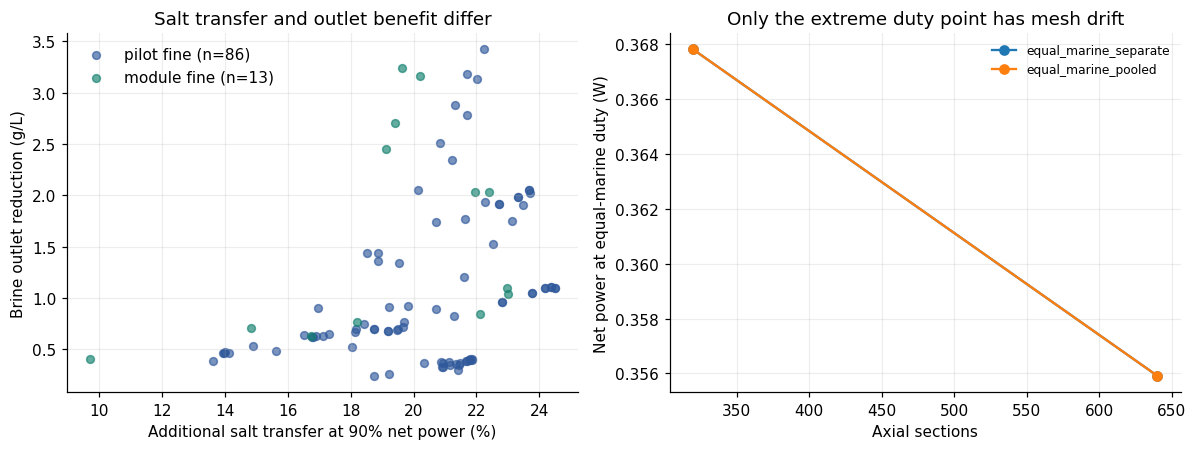

,claim,grade,evidence,limitation
0,90% net-power operating dial,fine within-model,86 distinct pilot design-closure cases (126 la...,Absolute power has structured benchmark mismat...
1,Membrane/dilute resources versus layout,screen plus selected fine,1323 fixed-resource spread rows; fine paired o...,"Compare matched N, phi, outlet mode and duty; ..."
2,Treatment-aware cost frontier,"fine candidate library, selection-gap review r...","108 matched policy rows and 4,000 shared cost ...",At φ=1 the screened 36-pair two-stage power-fi...
3,Equal-marine fresh duty at phi=1.5,withhold exact duty power,Pooled/separate duplicate design; 320-to-640 n...,Do not cite this duty point as converged.
4,Two-stage module at phi=1.0,fine confirmation missing,Two fine requests used twice the nominal dilut...,Nominal screen exists; corrected requests are ...


Final analysis tables, claim gate and figure written to /Users/Shared/blueleaflabs/osmoflux/analysis/final_submission_20261004_02


In [24]:
corrected=[]
for row in flow_audit.itertuples():
    old=next(json.loads((FINAL_RUN/'module/jobs'/row.job_id/'result.json').read_text())
             for _ in [0])['spec']
    ql=[float(v)/row.budget_ratio for v in old['ql']]
    corrected.append({'label':row.label,'N':old['N'],'phi':old['phi'],
                      'wiring':old['wiring'],'circuit':old['circuit'],
                      'na_json':json.dumps(old['na']),'corrected_ql_json':json.dumps(ql),
                      'q_h_m3_s':qh_module,'mesh_plan_json':json.dumps([160,320,640]),
                      'status':'NOT_RUN: corrected nominal-flow confirmation request'})
corrected_requests=export_final(pd.DataFrame(corrected),'module_corrected_fine_requests')
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
for study,data,color in [('pilot fine',pilot_unique_pairs,'#30599b'),('module fine',module_pairs_final,'#13806e')]:
    axs[0].scatter(data.salt_gain_pct,data.brine_outlet_drop_g_L,s=26,alpha=.65,label=f'{study} (n={len(data)})',color=color)
axs[0].set(xlabel='Additional salt transfer at 90% net power (%)',ylabel='Brine outlet reduction (g/L)',
           title='Salt transfer and outlet benefit differ')
axs[0].legend(frameon=False)
master_bad=fine_audit[fine_audit.study.eq('master')]
for row in master_bad.itertuples():
    axs[1].plot([320,640],[row.mesh_320_net_W,row.mesh_640_net_W],marker='o',label=row.objective.replace('duty_',''))
axs[1].set(xlabel='Axial sections',ylabel='Net power at equal-marine duty (W)',
           title='Only the extreme duty point has mesh drift')
axs[1].legend(frameon=False,fontsize=8)
fig.tight_layout()
fig.savefig(FINAL_OUT/'final_fine_audit.png',dpi=180,bbox_inches='tight')
fig.savefig(FINAL_OUT/'final_fine_audit.svg',bbox_inches='tight')
display(fig);plt.close(fig)
claim_rows=[
 {'claim':'90% net-power operating dial','grade':'fine within-model',
  'evidence':f'{len(pilot_unique_pairs)} distinct pilot design-closure cases ({len(pilot_pairs)} labeled rows) and {len(module_pairs_final)} valid module designs at 640 sections',
  'limitation':'Absolute power has structured benchmark mismatch; retain model-conditional wording.'},
 {'claim':'Membrane/dilute resources versus layout','grade':'screen plus selected fine',
  'evidence':f'{len(config_final)} fixed-resource spread rows; fine paired operating subset above',
  'limitation':'Compare matched N, phi, outlet mode and duty; do not pool heterogeneous cells.'},
 {'claim':'Treatment-aware cost frontier','grade':'fine candidate library, selection-gap review required',
  'evidence':f'{len(policy_pairs)} matched policy rows and 4,000 shared cost draws',
  'limitation':'At φ=1 the screened 36-pair two-stage power-first design meets the duty by 0.011 g/L but is absent from the fine library, whose selector jumps to 48 pairs. The 43% cost gap is therefore library-dependent; site costs remain unavailable.'},
 {'claim':'Equal-marine fresh duty at phi=1.5','grade':'withhold exact duty power',
  'evidence':'Pooled/separate duplicate design; 320-to-640 net-power drift exceeds 0.5% criterion',
  'limitation':'Do not cite this duty point as converged.'},
 {'claim':'Two-stage module at phi=1.0','grade':'fine confirmation missing',
  'evidence':'Two fine requests used twice the nominal dilute budget and produced no valid points',
  'limitation':'Nominal screen exists; corrected requests are recorded but not yet solved.'},
]
claim_gate=export_final(pd.DataFrame(claim_rows),'final_claim_gate')
summary={'run_id':FINAL_RUN.name,'pipeline_status':FINAL_STATUS['status'],
         'flagged_master_cases':int(fine_audit.study.eq('master').sum()),
         'invalid_module_fine_requests':int(flow_audit.invalid_flow_budget.sum()),
         'pilot_screen_pairs':len(master_screen_pairs),'module_screen_pairs':len(module_screen_pairs),
         'pilot_screen_median_90pct_salt_gain_pct':float(master_screen_pairs.salt_gain_pct.median()),
         'module_screen_median_90pct_salt_gain_pct':float(module_screen_pairs.salt_gain_pct.median()),
         'pilot_fine_pairs':len(pilot_pairs),'module_fine_pairs':len(module_pairs_final),
         'pilot_median_90pct_salt_gain_pct':float(pilot_pairs.salt_gain_pct.median()),
         'module_median_90pct_salt_gain_pct':float(module_pairs_final.salt_gain_pct.median()),
         'fine_tea_policy_pairs':len(policy_pairs),
         'fine_tea_median_saving_pct':float(policy_pairs.saving_pct.median()),
         'fine_tea_reference_phi1':reference_tea[['power_first','treatment_aware','saving_pct']].iloc[0].to_dict(),
         'fine_tea_reference_selected_N':selection_audit[['policy','N','selected_draws']].to_dict('records'),
         'fine_tea_reference_paired_saving_median_pct':float(paired_draws.paired_saving_pct.median()),
         'fine_tea_power_first_screen_gap':peak_threshold.to_dict('records'),
         'benchmark_power_mape':FINAL_STATUS['phases']['master']['benchmark_error']['power_mape']}
(FINAL_OUT/'FINAL_CLAIM_SNAPSHOT.json').write_text(json.dumps(summary,indent=2)+'\n')
display(claim_gate)
print('Final analysis tables, claim gate and figure written to',FINAL_OUT)


## H. Targeted v20 economics: resolve the candidate boundary

This final section is the **current economic analysis**. It reads the 58 completed add-on jobs under the final run ID, never invokes the RED solver, and leaves all run receipts unchanged. The study is limited to the 57.5/35.5 g L⁻¹ two-outlet partial duty at φ = 1.0. One-stage totals 18–42 and three two-stage layouts at 32–42 are compared with the main run's saved fine-library points; every new job used 160/320/640 axial sections. The 4,000 cost draws are paired between policies. Figure 11 replaces the earlier library-gap figure. Figure S8 shows why the minimum-area treatment design and the 90%-power operating result must not be conflated.

The section verifies its source hashes, checks the selected candidates against fine-passed physical rows, reconstructs the draw-level cost saving, and writes a new claim gate. A candidate with no qualifying point at the next lower tested pair count is not a proof of global infeasibility. Published-stack power error and missing site costs remain limitations.


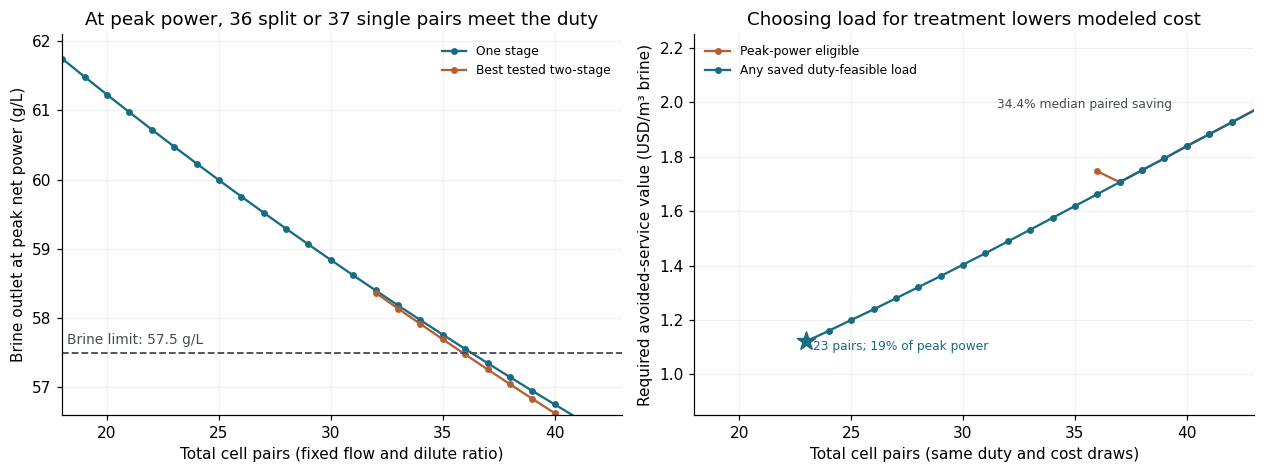

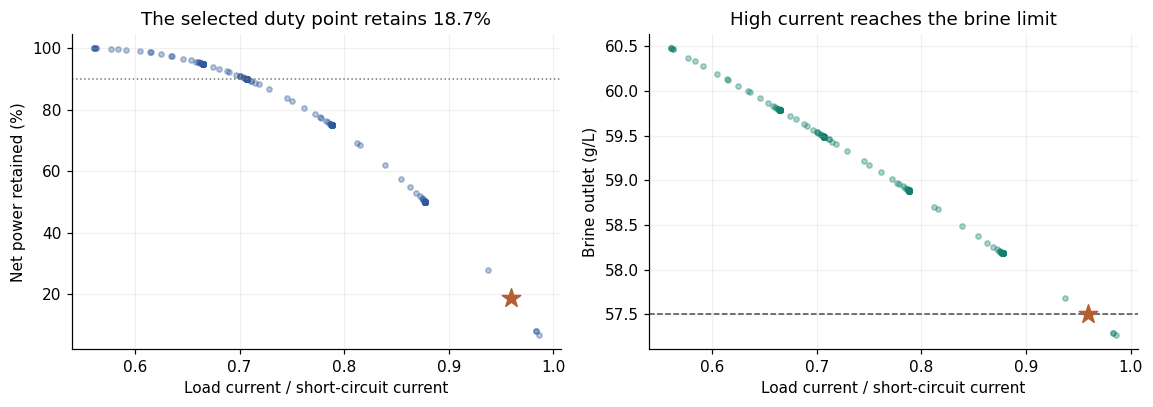

V20 ECONOMICS: 58/58 fine jobs; 4,000 paired draws
Selections: [{'policy': 'power_first', 'N': 37, 'stages': 1, 'draws': 3367, 'net_W': 3.5962031768091425, 'brine_margin_g_L': 0.14782298305608066}, {'policy': 'power_first', 'N': 36, 'stages': 2, 'draws': 633, 'net_W': 3.645554446775997, 'brine_margin_g_L': 0.02228125735875608}, {'policy': 'treatment_aware', 'N': 23, 'stages': 1, 'draws': 4000, 'net_W': 0.5069609615170956, 'brine_margin_g_L': -1.7337242752546445e-12}]
Paired saving median/p05/p95 (%): {0.5: 34.42857456996275, 0.05: 31.458941672066715, 0.95: 35.86641748910945}
Selected 23-pair net-power retention (%): 18.682752625767375
Current economic figures: /Users/Shared/blueleaflabs/osmoflux/paper/figures/v20_final_20261008/Fig11_v20_fine_economic_boundary.png /Users/Shared/blueleaflabs/osmoflux/paper/figures/v20_final_20261008/FigS8_v20_selected_load_curve.png


In [25]:
from pathlib import Path
import hashlib, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_h = Path(os.environ.get('OSMOFLUX_ROOT', '/Users/Shared/blueleaflabs/osmoflux')).resolve()
main_h = project_h/'runs_dev/REPRODUCIBILITY_E2E/final_submission_20261004_02'
addon_h = main_h/'v20_targeted_economics'
analysis_h = addon_h/'analysis'
out_h = Path(os.environ.get('OSMOFLUX_FINAL_ANALYSIS_OUTPUT', str(project_h/'analysis/final_submission_20261004_02'))).resolve()
out_h.mkdir(parents=True,exist_ok=True)
fig_h = project_h/'paper/figures/v20_final_20261008'
fig_h.mkdir(parents=True,exist_ok=True)
def hash_h(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
def decode_h(v):return json.loads(v) if isinstance(v,str) else v
def export_h(frame,name):
    frame.to_csv(out_h/f'{name}.csv',index=False)
    return frame
live_h=json.loads((addon_h/'LIVE_STATUS.json').read_text())
report_h=json.loads((analysis_h/'ADDON_REPORT.json').read_text())
baseline_h=json.loads((addon_h/'BASELINE_REPRODUCTION.json').read_text())
plan_h=json.loads((addon_h/'RUN_PLAN.json').read_text())
assert live_h['phase']=='COMPLETE' and live_h['completed']==live_h['planned']==58 and not live_h['failed']
assert report_h['status']=='ANALYSIS_COMPLETE' and report_h['completed_jobs']==58
assert baseline_h['status']=='PASS' and baseline_h['paired_draws']==4000
assert plan_h['main_run']==str(main_h)
for rel,expected in plan_h['pinned_sha256'].items():
    assert hash_h(main_h/'master'/rel)==expected,f'Main input changed: {rel}'
addon_inputs=['RUN_PLAN.json','BASELINE_REPRODUCTION.json','LIVE_STATUS.json',
    'analysis/ADDON_REPORT.json','analysis/fine_addon_points.parquet',
    'analysis/tea_candidates.parquet','analysis/tea_summary.parquet',
    'analysis/tea_resource_frontier.parquet',
    'analysis/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.parquet',
    'analysis/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_treatment_aware_None.parquet']
manifest_h={'main_run':str(main_h),'addon':str(addon_h),'main_input_sha256':plan_h['pinned_sha256'],
            'addon_sha256':{rel:hash_h(addon_h/rel) for rel in addon_inputs}}
(out_h/'V20_INPUT_MANIFEST.json').write_text(json.dumps(manifest_h,indent=2)+'\n')

old_h=pd.read_parquet(main_h/'master/fine_operating_points.parquet')
new_h=pd.read_parquet(analysis_h/'fine_addon_points.parquet')
variant_h=json.loads((main_h/'master/CONFIG.json').read_text())['physics']['selected_variant']
old_h=old_h[old_h.variant.eq(variant_h)].copy()
new_h=new_h[new_h.variant.eq(variant_h)].copy()
all_h=pd.concat([old_h,new_h],ignore_index=True)
all_h['spec_obj']=all_h.spec.map(decode_h)
all_h['N']=all_h.spec_obj.map(lambda x:x['N'])
all_h['S']=all_h.spec_obj.map(lambda x:len(x['na']))
all_h['phi']=all_h.spec_obj.map(lambda x:x['phi'])
all_h['qualified']=all_h.healthy.eq(True)&all_h.fine_pass.eq(True)&all_h.ch_out_g_L.le(57.5+1e-6)&all_h.cl_out_g_L.le(35.5+1e-6)
def key_h(r):
    return json.dumps(dict(spec=r.spec_obj,controls=decode_h(r.controls),variant=r.variant,
                           mesh=int(r.mesh),objective=r.objective),sort_keys=True)
all_h['candidate']=all_h.apply(key_h,axis=1)
new_h=all_h.iloc[len(old_h):].copy()
assert len(new_h)==575 and new_h.N.between(18,42).all()
assert len(list((addon_h/'jobs').glob('*/receipt.json')))==58

power_h=pd.read_parquet(analysis_h/'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.parquet')
treat_h=pd.read_parquet(analysis_h/'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_treatment_aware_None.parquet')
paired_h=power_h.merge(treat_h,on='draw',suffixes=('_power','_treat'),validate='one_to_one')
assert len(paired_h)==4000 and paired_h.feasible_power.all() and paired_h.feasible_treat.all()
paired_h['saving_pct']=100*(1-paired_h.signed_required_value_USD_m3_treat/paired_h.signed_required_value_USD_m3_power)
assert abs(paired_h.saving_pct.median()-report_h['paired_saving_pct']['median'])<1e-9
assert abs(paired_h.saving_pct.quantile(.05)-report_h['paired_saving_pct']['p05'])<1e-9
assert abs(paired_h.saving_pct.quantile(.95)-report_h['paired_saving_pct']['p95'])<1e-9
export_h(paired_h[['draw','candidate_power','candidate_treat','signed_required_value_USD_m3_power',
                   'signed_required_value_USD_m3_treat','saving_pct']],'v20_phi1_paired_economics')
selected_h=[]
lookup_h=all_h[all_h.healthy.eq(True)&all_h.fine_pass.eq(True)].drop_duplicates('candidate').set_index('candidate')
for policy,table in [('power_first',power_h),('treatment_aware',treat_h)]:
    for candidate,count in table.candidate.value_counts().items():
        assert candidate in lookup_h.index
        row=lookup_h.loc[candidate]
        assert bool(row.qualified)
        if policy=='power_first':assert row.objective=='peak'
        selected_h.append(dict(policy=policy,draws=int(count),fraction=float(count/len(table)),
            N=int(row.N),stages=int(row.S),objective=row.objective,source_label=row.label,
            ch_out_g_L=float(row.ch_out_g_L),cl_out_g_L=float(row.cl_out_g_L),
            brine_margin_g_L=float(57.5-row.ch_out_g_L),dilute_margin_g_L=float(35.5-row.cl_out_g_L),
            net_W=float(row.net_W),controls_json=json.dumps(decode_h(row.controls))))
selected_h=export_h(pd.DataFrame(selected_h),'v20_phi1_selected_designs')
assert set(selected_h.loc[selected_h.policy.eq('treatment_aware'),'N'])=={23}
assert set(selected_h.loc[selected_h.policy.eq('power_first'),'N'])=={36,37}
peak23_h=new_h[(new_h.N==23)&new_h.S.eq(1)&new_h.objective.eq('peak')].iloc[0]
duty23_h=new_h[(new_h.N==23)&new_h.S.eq(1)&new_h.objective.eq('duty_partial_treatment_pooled')].iloc[0]
retention23_h=float(duty23_h.net_W/peak23_h.net_W)
assert duty23_h.fine_pass and peak23_h.fine_pass and .18<retention23_h<.20
n22_h=new_h[(new_h.N==22)&new_h.S.eq(1)&new_h.objective.eq('peak')]
assert len(n22_h)==1 and bool(n22_h.fine_pass.iloc[0])

cost_h=pd.read_parquet(analysis_h/'tea_candidates.parquet')
cost_h=cost_h[cost_h.baseline.eq('existing_dilute_service')].copy()
cost_h=cost_h.merge(all_h[['candidate','qualified','N','S','objective','ch_out_g_L']].drop_duplicates('candidate'),
                    on='candidate',how='left',validate='one_to_one',suffixes=('','_physical'))
assert cost_h.qualified.notna().all()
cost_h=cost_h[cost_h.qualified.eq(True)&cost_h.phi.eq(1.0)].copy()
cost_h['policy_class']=np.where(cost_h.objective.eq('peak'),'power_first','treatment_aware')
frontier_h=[]
for N,g in cost_h.groupby('N'):
    for policy,subset in [('power_first',g[g.objective.eq('peak')]),('treatment_aware',g)]:
        if len(subset):
            best=subset.loc[subset.signed_required_value_median_USD_m3.idxmin()]
            frontier_h.append(dict(N=int(N),policy=policy,
                best_candidate_median_USD_m3=float(best.signed_required_value_median_USD_m3),
                candidate=best.candidate,stages=int(best.S),candidate_count=len(subset)))
frontier_h=export_h(pd.DataFrame(frontier_h),'v20_phi1_candidate_frontier')

# Figure 11: physical boundary and economic consequence share the membrane axis.
new_peaks_h=new_h[(new_h.objective.eq('peak'))&new_h.fine_pass.eq(True)&new_h.healthy.eq(True)&new_h.phi.eq(1)].copy()
fig,axs=plt.subplots(1,2,figsize=(11.6,4.4))
for stages,color,label in [(1,'#176b83','One stage'),(2,'#b75d32','Best tested two-stage')]:
    group=new_peaks_h[new_peaks_h.S.eq(stages)].groupby('N',as_index=False).ch_out_g_L.min().sort_values('N')
    axs[0].plot(group.N,group.ch_out_g_L,marker='o',markersize=3.5,color=color,label=label)
axs[0].axhline(57.5,color='#454d54',linestyle='--',linewidth=1.2)
axs[0].text(18.2,57.63,'Brine limit: 57.5 g/L',fontsize=9,color='#454d54')
axs[0].set(xlabel='Total cell pairs (fixed flow and dilute ratio)',ylabel='Brine outlet at peak net power (g/L)',
    title='At peak power, 36 split or 37 single pairs meet the duty',xlim=(18,43),ylim=(56.6,62.1))
axs[0].legend(frameon=False,loc='upper right',fontsize=8)
for policy,color,label in [('power_first','#b75d32','Peak-power eligible'),('treatment_aware','#176b83','Any saved duty-feasible load')]:
    g=frontier_h[frontier_h.policy.eq(policy)].sort_values('N')
    axs[1].plot(g.N,g.best_candidate_median_USD_m3,marker='o',markersize=3.5,color=color,label=label)
axs[1].scatter([23 if policy=='treatment_aware' else 37],[1.1213153302550178 if policy=='treatment_aware' else 1.705577496629353],
        marker='*',s=155,color=color,zorder=5)
axs[1].set(xlabel='Total cell pairs (same duty and cost draws)',
    ylabel='Required avoided-service value (USD/m³ brine)',
    title='Choosing load for treatment lowers modeled cost',xlim=(18,43),ylim=(0.85,2.25))
axs[1].legend(frameon=False,loc='upper left',fontsize=8)
axs[1].text(23.3,1.09,'23 pairs; 19% of peak power',fontsize=8,color='#176b83')
axs[1].text(31.5,1.98,'34.4% median paired saving',fontsize=8,color='#454d54')
for ax in axs:
    ax.spines[['top','right']].set_visible(False)
    ax.grid(alpha=.18)
fig.tight_layout()
fig11_h=fig_h/'Fig11_v20_fine_economic_boundary.png'
fig.savefig(fig11_h,dpi=200,bbox_inches='tight')
fig.savefig(fig_h/'Fig11_v20_fine_economic_boundary.svg',bbox_inches='tight')
display(fig);plt.close(fig)

# Figure S8: the chosen 23-pair duty point lies well below the 90% operating rung.
result23_h=json.loads((addon_h/'jobs/N23_one_stage/result.json').read_text())
level640_h=next(level for level in result23_h['levels'] if level['mesh']==640)
trials23_h=pd.DataFrame(json.loads(Path(level640_h['trials_path']).read_text()))
trials23_h=trials23_h[trials23_h.healthy.eq(True)&trials23_h.net_W.ge(0)].copy()
trials23_h['current_fraction']=trials23_h.controls.map(lambda c:decode_h(c)[0])
trials23_h=trials23_h[trials23_h.current_fraction.ge(decode_h(peak23_h.controls)[0])]
fig,axs=plt.subplots(1,2,figsize=(10.6,3.8),sharex=True)
axs[0].scatter(trials23_h.current_fraction,100*trials23_h.net_W/peak23_h.net_W,s=12,alpha=.35,color='#30599b')
axs[0].scatter([decode_h(duty23_h.controls)[0]],[100*retention23_h],marker='*',s=160,color='#b75d32',zorder=5)
axs[0].axhline(90,color='#777',linestyle=':',linewidth=1)
axs[0].set(ylabel='Net power retained (%)',title='The selected duty point retains 18.7%')
axs[1].scatter(trials23_h.current_fraction,trials23_h.ch_out_g_L,s=12,alpha=.35,color='#13806e')
axs[1].scatter([decode_h(duty23_h.controls)[0]],[duty23_h.ch_out_g_L],marker='*',s=160,color='#b75d32',zorder=5)
axs[1].axhline(57.5,color='#454d54',linestyle='--',linewidth=1)
axs[1].set(ylabel='Brine outlet (g/L)',title='High current reaches the brine limit')
for ax in axs:
    ax.set_xlabel('Load current / short-circuit current')
    ax.spines[['top','right']].set_visible(False)
    ax.grid(alpha=.18)
fig.tight_layout()
figs8_h=fig_h/'FigS8_v20_selected_load_curve.png'
fig.savefig(figs8_h,dpi=200,bbox_inches='tight')
fig.savefig(fig_h/'FigS8_v20_selected_load_curve.svg',bbox_inches='tight')
display(fig);plt.close(fig)

# Replace the obsolete pre-add-on economic gate and snapshot with audited current claims.
gate_path_h=out_h/'final_claim_gate.csv'
if gate_path_h.exists():
    gate_h=pd.read_csv(gate_path_h)
    mask=gate_h.claim.eq('Treatment-aware cost frontier')
    gate_h.loc[mask,'grade']='fine local candidate family; conditional economics'
    gate_h.loc[mask,'evidence']='58 completed add-on designs at 160/320/640 sections, 4,000 paired cost draws; peak selects 36/37 pairs, treatment selects 23'
    gate_h.loc[mask,'limitation']='At 23 pairs the duty retains 18.7% of peak net power; one phi=1 partial duty, finite candidate family, no site costs or validated absolute power.'
    export_h(gate_h,'final_claim_gate')
snapshot_path_h=out_h/'FINAL_CLAIM_SNAPSHOT.json'
snapshot_h=json.loads(snapshot_path_h.read_text()) if snapshot_path_h.exists() else {}
snapshot_h.update(dict(economic_source='v20_targeted_economics',addon_jobs_completed=58,
    addon_nominal_candidate_count=int(json.loads((analysis_h/'TEA_CANDIDATE_AUDIT.json').read_text())['eligible_after_exact_dominance']),
    fine_tea_reference_phi1=dict(power_first=report_h['combined_medians_USD_m3']['power_first'],
                                 treatment_aware=report_h['combined_medians_USD_m3']['treatment_aware']),
    fine_tea_reference_selected_N=selected_h[['policy','N','draws']].to_dict('records'),
    fine_tea_reference_paired_saving_median_pct=float(paired_h.saving_pct.median()),
    fine_tea_reference_paired_saving_p05_pct=float(paired_h.saving_pct.quantile(.05)),
    fine_tea_reference_paired_saving_p95_pct=float(paired_h.saving_pct.quantile(.95)),
    treatment_selected_power_retention_pct=100*retention23_h,
    prior_fine_library_cost_pair=dict(power_first=report_h['baseline_medians_USD_m3']['power_first'],
                                      treatment_aware=report_h['baseline_medians_USD_m3']['treatment_aware']),
    figure_11=str(fig11_h.relative_to(project_h)),supplement_figure_8=str(figs8_h.relative_to(project_h)),
    economic_claim_scope='phi=1.0 partial two-outlet duty, nominal NaCl model, tested candidate family, conditional costs'))
snapshot_path_h.write_text(json.dumps(snapshot_h,indent=2)+'\n')
print('V20 ECONOMICS: 58/58 fine jobs; 4,000 paired draws')
print('Selections:',selected_h[['policy','N','stages','draws','net_W','brine_margin_g_L']].to_dict('records'))
print('Paired saving median/p05/p95 (%):',paired_h.saving_pct.quantile([.5,.05,.95]).to_dict())
print('Selected 23-pair net-power retention (%):',100*retention23_h)
print('Current economic figures:',fig11_h,figs8_h)


## I. Final saved-data challenge: does the load lever outrank rearrangement under the fouling scenarios?

This section **does not solve the physical model**. It verifies and reanalyzes the completed 40-section fouling matrix (720 rows = 2 scales × 6 dilute ratios × 5 layouts × 6 severities × 2 operating points) and the 4,000 saved paired economic draws.

For each scale, dilute ratio, and severity, the *load lever* is the one-stage brine-outlet decrease from its own peak-net-power point to its own 90%-retention higher-current point. The *best tested rearrangement* is the extra brine-outlet decrease from that one-stage 90%-retention point to the lowest outlet among five layouts, each at **90% of its own peak net power**. These are equal-membrane/equal-dilute comparisons, but **not matched-absolute-power architecture comparisons**. A positive difference establishes a ranking only in this saved cohort. The `membrane_high` scenario uses `FOULING_BETA=1.2` and `DIVALENT_FRACTION=0.2` in a concentration-dependent resistance formula; it is not a uniform +120% resistance multiplier.

The economic calculation adds illustrative policy-common costs *after* the saved paired draws. It changes no cost input in the physics or TEA run. Such costs cancel from the **absolute** difference if they truly are identical per cubic metre for both policies, while reducing the reported **percentage** difference. Design-dependent site costs would not cancel.

In [26]:
# Section I: audit only saved run data; no RED solver calls.
from pathlib import Path
import json
import numpy as np
import pandas as pd

fouling_rel_i='fouling_matrix/fouling_paired.parquet'
recorded_i=CATALOG.loc[CATALOG.path.eq(fouling_rel_i),'sha256']
assert len(recorded_i)==1 and sha256(FINAL_RUN/fouling_rel_i)==recorded_i.iloc[0]
f_i=pd.read_parquet(FINAL_RUN/fouling_rel_i)
assert len(f_i)==720 and f_i.healthy.all() and f_i.mesh.eq(40).all()
assert set(f_i.objective)=={'peak','salt_0.9'}
assert set(f_i.design)=={'single','serial_2','serial_4','fresh_2','fresh_4'}
assert set(f_i.scale)=={'pilot','module'}
assert set(f_i.severity)=={'clean','membrane_low','membrane_mid','membrane_high','channel_only','combined'}
assert set(f_i.phi)=={.25,.5,.75,1.,1.5,2.}
assert f_i.groupby(['scale','phi','severity','design','objective']).size().eq(1).all()
rows_i=[]
for (scale_i,phi_i,severity_i),g_i in f_i.groupby(['scale','phi','severity'],sort=True):
    peak_i=g_i[(g_i.design=='single')&(g_i.objective=='peak')].iloc[0]
    load_i=g_i[(g_i.design=='single')&(g_i.objective=='salt_0.9')].iloc[0]
    layouts_i=g_i[g_i.objective.eq('salt_0.9')]
    best_i=layouts_i.loc[layouts_i.ch_out_g_L.idxmin()]
    load_drop_i=float(peak_i.ch_out_g_L-load_i.ch_out_g_L)
    layout_drop_i=float(load_i.ch_out_g_L-best_i.ch_out_g_L)
    rows_i.append(dict(scale=scale_i,phi=phi_i,severity=severity_i,mesh=40,
        N=int(peak_i.N),load_drop_g_L=load_drop_i,
        best_rearrangement_drop_g_L=layout_drop_i,
        load_minus_rearrangement_g_L=load_drop_i-layout_drop_i,
        load_to_rearrangement_ratio=load_drop_i/layout_drop_i if layout_drop_i>0 else np.nan,
        best_design=best_i.design,
        single_peak_net_W=float(peak_i.net_W),single_90pct_net_W=float(load_i.net_W),
        best_layout_90pct_net_W=float(best_i.net_W),
        single_90pct_salt_gain_pct=100*(float(load_i.salt_mol_s)/float(peak_i.salt_mol_s)-1)))
case_i=pd.DataFrame(rows_i)
assert len(case_i)==72 and case_i.load_minus_rearrangement_g_L.gt(0).all()
assert case_i.load_drop_g_L.gt(0).all() and case_i.best_rearrangement_drop_g_L.ge(0).all()
summary_i=(case_i.groupby(['scale','severity'],as_index=False)
    .agg(n_phi=('phi','size'),median_load_drop_g_L=('load_drop_g_L','median'),
         median_best_rearrangement_drop_g_L=('best_rearrangement_drop_g_L','median'),
         min_load_minus_rearrangement_g_L=('load_minus_rearrangement_g_L','min'),
         median_salt_gain_pct=('single_90pct_salt_gain_pct','median')))
summary_i['ratio_of_median_drops']=summary_i.median_load_drop_g_L/summary_i.median_best_rearrangement_drop_g_L
assert summary_i.n_phi.eq(6).all()
case_i.to_csv(FINAL_OUT/'final_fouling_lever_cases.csv',index=False)
summary_i.to_csv(FINAL_OUT/'final_fouling_lever_summary.csv',index=False)

# Illustration only: a cost common to both policies in every paired draw.
power_i=paired_h.signed_required_value_USD_m3_power.to_numpy(float)
treat_i=paired_h.signed_required_value_USD_m3_treat.to_numpy(float)
assert len(power_i)==len(treat_i)==4000 and np.isfinite(power_i).all() and np.isfinite(treat_i).all()
difference_i=power_i-treat_i
assert (difference_i>=-1e-9).all()
cost_i=[]
for common_i in (0.,.5,1.,2.):
    saving_i=100*difference_i/(power_i+common_i)
    cost_i.append(dict(illustrative_common_site_cost_USD_m3=common_i,draws=len(power_i),
       median_power_first_required_USD_m3=float(np.median(power_i+common_i)),
       median_treatment_first_required_USD_m3=float(np.median(treat_i+common_i)),
       median_paired_absolute_saving_USD_m3=float(np.median(difference_i)),
       median_paired_percent_saving=float(np.median(saving_i)),
       p05_paired_percent_saving=float(np.quantile(saving_i,.05)),
       p95_paired_percent_saving=float(np.quantile(saving_i,.95))))
common_i_df=pd.DataFrame(cost_i)
assert abs(common_i_df.iloc[0].median_paired_percent_saving-34.42857456996275)<1e-9
assert common_i_df.median_paired_absolute_saving_USD_m3.nunique()==1
common_i_df.to_csv(FINAL_OUT/'final_common_cost_sensitivity.csv',index=False)
ledger_i=dict(source_fouling_parquet=fouling_rel_i,source_fouling_sha256=recorded_i.iloc[0],
     fouling_rows=len(f_i),case_count=len(case_i),all_72_load_greater_than_best_rearrangement=True,
     minimum_margin_g_L=float(case_i.load_minus_rearrangement_g_L.min()),
     minimum_margin_case=case_i.loc[case_i.load_minus_rearrangement_g_L.idxmin(),
         ['scale','phi','severity','load_drop_g_L','best_rearrangement_drop_g_L']].to_dict(),
     metric_scope='40-section; equal N and phi; five layouts at 90% of their own peak net power, not matched absolute power',
     severity_scope='concentration-dependent membrane proxy; membrane_high means beta=1.2 and divalent fraction=0.2, not +120% ASR',
     cost_scope='illustrative policy-common additive cost; no site estimate and no new TEA or physics run',
     paired_absolute_saving_median_USD_m3=float(np.median(difference_i)))
(FINAL_OUT/'FINAL_SAVED_DATA_CHALLENGE.json').write_text(json.dumps(ledger_i,indent=2)+'\n')
print('Saved-data challenge: 72/72 load drops exceed best tested rearrangement.')
print('Smallest margin (g/L):',ledger_i['minimum_margin_case'],'margin',ledger_i['minimum_margin_g_L'])
print(summary_i[['scale','severity','median_load_drop_g_L','median_best_rearrangement_drop_g_L','ratio_of_median_drops']].round(3).to_string(index=False))
print('Common-cost illustration:')
print(common_i_df[['illustrative_common_site_cost_USD_m3','median_paired_absolute_saving_USD_m3','median_paired_percent_saving']].round(3).to_string(index=False))


Saved-data challenge: 72/72 load drops exceed best tested rearrangement.
Smallest margin (g/L): {'scale': 'module', 'phi': 0.25, 'severity': 'clean', 'load_drop_g_L': 0.6782670381259521, 'best_rearrangement_drop_g_L': 0.6247985568267467} margin 0.05346848129920545
 scale      severity  median_load_drop_g_L  median_best_rearrangement_drop_g_L  ratio_of_median_drops
module  channel_only                 1.520                               0.300                  5.073
module         clean                 1.662                               0.418                  3.976
module      combined                 1.356                               0.230                  5.905
module membrane_high                 1.395                               0.286                  4.874
module  membrane_low                 1.562                               0.366                  4.271
module  membrane_mid                 1.474                               0.322                  4.571
 pilot  channel_only 

## J. Hulme workbook-verified benchmark for manuscript v21

Run this section alone to regenerate the 18-row observed-versus-modeled table, per-stack errors and Figure 10 from the verified deposited workbook and completed 640-section diagnostic. It reads the original 40-section benchmark for the manuscript's run-of-record error, and explicitly keeps that separate from the 640-section sensitivity. No RED solver is called and no source result is modified. Outputs are saved under `analysis/final_submission_20261004_02/`.


In [ ]:
# Section J: verified Hulme workbook comparison. Saved-data analysis only.
from pathlib import Path
import hashlib, json, os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

project_j = Path(os.environ.get('OSMOFLUX_ROOT', '/Users/Shared/blueleaflabs/osmoflux')).resolve()
run_j = project_j/'runs_dev/REPRODUCIBILITY_E2E/final_submission_20261004_02'
verified_j = project_j/'runs_dev/HULME_WORKBOOK_VERIFICATION_final_submission_20261004_02'
fine_j = run_j/'hulme_unfloored_640'
out_j = Path(os.environ.get('OSMOFLUX_FINAL_ANALYSIS_OUTPUT', str(project_j/'analysis/final_submission_20261004_02'))).resolve()
out_j.mkdir(parents=True, exist_ok=True)

def sha_j(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

status_j = json.loads((fine_j/'RUN_STATUS.json').read_text())
assert status_j['status']=='COMPLETE' and status_j['completed']==36 and not status_j['failed']
verified_path_j = verified_j/'hulme_unified_experiment_vs_osmoflux.csv'
fine_path_j = fine_j/'results.csv'
screen_path_j = run_j/'master/benchmark_comparison.parquet'
for path_j in [verified_path_j, fine_path_j, screen_path_j]:
    assert path_j.is_file(), path_j
source_manifest_j = json.loads((verified_j/'SOURCE_VERIFICATION.json').read_text())
fine_manifest_j = json.loads((fine_j/'SOURCE_MANIFEST.json').read_text())
assert fine_manifest_j['benchmarks_plan.json']==sha_j(run_j/'master/benchmarks_plan.json')

obs_j = pd.read_csv(verified_path_j)
obs_j = obs_j[obs_j.high_feed_M.eq(0.51)].copy()
assert len(obs_j)==18 and obs_j[['stack_cm','reported_flow_L_min']].drop_duplicates().shape[0]==18
assert obs_j.low_feed_M.eq(0.02).all() and obs_j.cell_pairs.eq(25).all()
fine_rows_j = pd.read_csv(fine_path_j)
assert len(fine_rows_j)==36 and fine_rows_j.status.eq('COMPLETE').all()
assert set(fine_rows_j.variant)=={'nominal','unfloored'} and fine_rows_j.mesh.eq(640).all()
screen_j = pd.read_parquet(screen_path_j)
screen_j = screen_j[(screen_j.source=='0.51M')&(screen_j.variant=='common_voltage_bulk')].copy()
assert len(screen_j)==18

rows_j=[]
for row_j in obs_j.itertuples():
    key_j=(fine_rows_j['stack'].eq(row_j.stack_cm)&
           np.isclose(fine_rows_j.flow_L_min,row_j.reported_flow_L_min,atol=1e-10))
    f_j=fine_rows_j[key_j]
    assert len(f_j)==2
    nominal_j=f_j[f_j.variant.eq('nominal')].iloc[0]
    nofloor_j=f_j[f_j.variant.eq('unfloored')].iloc[0]
    old_j=screen_j[(screen_j['stack']==row_j.stack_cm)&
                   np.isclose(screen_j.flow_Lmin,row_j.reported_flow_L_min,atol=1e-10)]
    assert len(old_j)==1
    assert abs(nominal_j.observed_peak_W_m2-row_j.measured_peak_gross_pd_W_m2)<1e-6
    assert abs(nofloor_j.observed_ocv_V-row_j.measured_ocv_V)<1e-6
    rows_j.append(dict(stack_cm=row_j.stack_cm,flow_L_min=row_j.reported_flow_L_min,
      residence_s=row_j.nominal_channel_residence_s,
      measured_gross_W_m2=row_j.measured_peak_gross_pd_W_m2,
      measured_gross_sd_W_m2=row_j.measured_peak_gross_pd_sd_W_m2,
      measured_ocv_V=row_j.measured_ocv_V,measured_ocv_sd_V=row_j.measured_ocv_sd_V,
      nominal_40_power_ratio=float(old_j.iloc[0].power_ratio),
      nominal_640_gross_W_m2=nominal_j.model_peak_W_m2,
      nominal_640_ocv_V=nominal_j.model_ocv_V,
      unfloored_640_gross_W_m2=nofloor_j.model_peak_W_m2,
      unfloored_640_ocv_V=nofloor_j.model_ocv_V,
      nominal_640_power_error_pct=100*(nominal_j.power_ratio-1),
      unfloored_640_power_error_pct=100*(nofloor_j.power_ratio-1)))
joined_j=pd.DataFrame(rows_j).sort_values(['stack_cm','flow_L_min'])
joined_j.to_csv(out_j/'hulme_v21_observations_and_predictions.csv',index=False)

summary_j=[]
for variant_j in ['nominal_40','nominal_640','unfloored_640']:
    for stack_j in ['all','10x10','10x20','10x40']:
        group_j=joined_j if stack_j=='all' else joined_j[joined_j.stack_cm.eq(stack_j)]
        if variant_j=='nominal_40':
            ratio_j=group_j.nominal_40_power_ratio.to_numpy(float)
        else:
            pred_col_j=variant_j+'_gross_W_m2'
            ratio_j=group_j[pred_col_j].to_numpy(float)/group_j.measured_gross_W_m2.to_numpy(float)
        summary_j.append(dict(variant=variant_j,stack=stack_j,n=len(group_j),
              power_mape_pct=float(100*np.mean(np.abs(ratio_j-1))),
              median_power_ratio=float(np.median(ratio_j))))
summary_j=pd.DataFrame(summary_j)
summary_j.to_csv(out_j/'hulme_v21_power_error_summary.csv',index=False)
assert abs(summary_j[(summary_j.variant=='nominal_40')&(summary_j['stack']=='all')].power_mape_pct.iloc[0]-41.757)<.02
assert abs(summary_j[(summary_j.variant=='nominal_640')&(summary_j['stack']=='all')].power_mape_pct.iloc[0]-41.251)<.02
assert abs(summary_j[(summary_j.variant=='unfloored_640')&(summary_j['stack']=='all')].power_mape_pct.iloc[0]-23.763)<.02

# Figure 10: same horizontal axis for observed power and voltage, with workbook SDs.
fig_j,axs_j=plt.subplots(2,1,figsize=(8.5,8.0),sharex=True,constrained_layout=True)
palette_j={'10x10':'#176b83','10x20':'#b05a30','10x40':'#694d92'}
for stack_j,color_j in palette_j.items():
    g_j=joined_j[joined_j.stack_cm.eq(stack_j)].sort_values('residence_s')
    axs_j[0].errorbar(g_j.residence_s,g_j.measured_gross_W_m2,
       yerr=g_j.measured_gross_sd_W_m2,fmt='o',markersize=5,capsize=2.5,
       color=color_j,label=f'{stack_j} cm measured')
    axs_j[1].errorbar(g_j.residence_s,g_j.measured_ocv_V,
       yerr=g_j.measured_ocv_sd_V,fmt='o',markersize=5,capsize=2.5,
       color=color_j,label=f'{stack_j} cm measured')
line_j=joined_j.sort_values('residence_s')
for ax_j,nomcol_j,altcol_j in [
    (axs_j[0],'nominal_640_gross_W_m2','unfloored_640_gross_W_m2'),
    (axs_j[1],'nominal_640_ocv_V','unfloored_640_ocv_V')]:
    ax_j.plot(line_j.residence_s,line_j[nomcol_j],color='#1d2733',lw=2.0,label='Nominal model, 640 sections')
    ax_j.plot(line_j.residence_s,line_j[altcol_j],color='#666666',lw=1.8,ls='--',label='Floor-free diagnostic, 640 sections')
    ax_j.set_xscale('log')
    ax_j.grid(alpha=.2,which='both')
    ax_j.spines[['top','right']].set_visible(False)
axs_j[0].set_ylabel('Peak gross power density (W m$^{-2}$)')
axs_j[1].set_ylabel('Open-circuit voltage (V)')
axs_j[1].set_xlabel('Nominal channel residence time (s)')
axs_j[0].set_title('Published stack measurements do not collapse onto one residence-time curve',loc='left',fontsize=11,weight='bold')
axs_j[0].legend(ncol=2,fontsize=8,loc='upper right',frameon=False)
axs_j[0].annotate('10×20 below both neighbors at 18.6 s',xy=(18.6,.572),xytext=(28,.28),
    arrowprops=dict(arrowstyle='->',lw=1,color='#777777'),fontsize=8,color='#814322')
fig_j.savefig(out_j/'Fig10_benchmark_v21.png',dpi=220,bbox_inches='tight')
fig_j.savefig(out_j/'Fig10_benchmark_v21.svg',bbox_inches='tight')
plt.close(fig_j)

(out_j/'HULME_V21_INPUT_MANIFEST.json').write_text(json.dumps(dict(
    workbook_verified_table_sha256=sha_j(verified_path_j),
    benchmark_40_sha256=sha_j(screen_path_j),
    fine_640_results_sha256=sha_j(fine_path_j),
    source_verification=source_manifest_j,
    fine_source_manifest=fine_manifest_j,
    output=['hulme_v21_observations_and_predictions.csv','hulme_v21_power_error_summary.csv',
            'Fig10_benchmark_v21.png','Fig10_benchmark_v21.svg']),indent=2,default=str)+'\n')
print(summary_j.to_string(index=False,float_format=lambda x:f'{x:.2f}'))
print('Wrote verified Hulme tables and revised Figure 10 to',out_j)


## K. v23 editorial evidence audit

Recompute exact matched-residence Hulme ratios and the paired economic summary from frozen source files. This section reads saved data only and writes audit tables under `analysis/final_submission_20261004_02/`.


In [ ]:
from pathlib import Path
from itertools import combinations
import hashlib, json
import numpy as np
import pandas as pd

ROOT = Path('/Users/Shared/blueleaflabs/osmoflux')
OUT = ROOT / 'analysis/final_submission_20261004_02'
benchmark = OUT / 'hulme_v21_observations_and_predictions.csv'
resistance = ROOT / 'runs_dev/REPRODUCIBILITY_E2E/final_submission_20261004_02/hulme_apparent_resistance/apparent_resistance_18_points.csv'
unified_benchmark = ROOT / 'runs_dev/HULME_WORKBOOK_VERIFICATION_final_submission_20261004_02/hulme_unified_experiment_vs_osmoflux.csv'
fine_benchmark_jobs = ROOT / 'runs_dev/REPRODUCIBILITY_E2E/final_submission_20261004_02/hulme_unfloored_640/jobs'
tea = ROOT / 'runs_dev/REPRODUCIBILITY_E2E/final_submission_20261004_02/v20_targeted_economics/analysis'
power_selection = tea / 'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.csv'
treatment_selection = tea / 'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_treatment_aware_None.csv'
tea_candidates = tea / 'tea_candidates.csv'
plant_scale = tea / 'plant_scale.csv'
fine_points = tea / 'fine_addon_points.csv'
inputs = [benchmark, resistance, unified_benchmark, power_selection, treatment_selection, tea_candidates, plant_scale, fine_points]
for p in inputs:
    if not p.exists(): raise FileNotFoundError(p)

b = pd.read_csv(benchmark)
pair_rows=[]
for residence, group in b.groupby('residence_s'):
    if len(group)<2: continue
    for a,c in combinations(group.to_dict('records'),2):
        x,y=sorted((a,c),key=lambda r: int(r['stack_cm'].split('x')[1]))
        measured=y['measured_gross_W_m2']/x['measured_gross_W_m2']
        nominal=y['nominal_640_gross_W_m2']/x['nominal_640_gross_W_m2']
        diff=y['measured_gross_W_m2']-x['measured_gross_W_m2']
        combined_sd=np.hypot(y['measured_gross_sd_W_m2'],x['measured_gross_sd_W_m2'])
        pair_rows.append({'residence_s':residence,'numerator_stack':y['stack_cm'],'denominator_stack':x['stack_cm'],
                          'measured_power_ratio':measured,'nominal_640_power_ratio':nominal,
                          'measured_power_difference_W_m2':diff,'combined_reported_SD_W_m2':combined_sd,
                          'difference_over_combined_SD':abs(diff)/combined_sd})
pairs=pd.DataFrame(pair_rows).sort_values(['residence_s','numerator_stack','denominator_stack'])
assert len(pairs)==10, len(pairs)
assert np.allclose(pairs['nominal_640_power_ratio'],1.0,atol=0.003)
mean_diff=pairs[(pairs.residence_s==18.6)&(pairs.numerator_stack=='10x20')]
assert len(mean_diff)==1
res=pd.read_csv(resistance)
res_summary=(res.assign(model_over_measured=res.model_secant_pair_ohm_cm2/res.observed_secant_pair_ohm_cm2)
             .groupby('stack_cm').model_over_measured.median().to_dict())
u=pd.read_csv(unified_benchmark)
u=u[u.high_feed_M.between(0.50,0.52)].copy()
receipts=[]
for p in sorted(fine_benchmark_jobs.glob('nominal_*/result.json')):
    record=json.loads(p.read_text())
    assert record['status']=='COMPLETE' and record['mesh']==640
    receipts.append(record)
assert len(receipts)==18
f=pd.DataFrame(receipts)
sec=u.merge(f,left_on=['stack_cm','reported_flow_L_min'],right_on=['stack','flow_L_min'],validate='one_to_one')
sec['observed_secant_ohm_cm2']=(sec.measured_ocv_V/sec.measured_max_current_A)*sec.active_sheet_area_m2/sec.cell_pairs*1e4
sec['model_640_secant_ohm_cm2']=(sec.model_ocv_V_y/sec.model_short_circuit_current_A_y)*sec.active_sheet_area_m2/sec.cell_pairs*1e4
sec['model_over_observed_640']=sec.model_640_secant_ohm_cm2/sec.observed_secant_ohm_cm2
sec['observed_secant_reported_SD_ohm_cm2']=sec.observed_secant_ohm_cm2*np.hypot(sec.measured_ocv_sd_V/sec.measured_ocv_V,sec.measured_max_current_sd_A/sec.measured_max_current_A)
sec_summary=sec.groupby('stack_cm').model_over_observed_640.median().to_dict()
sec_cols=['stack_cm','reported_flow_L_min','nominal_channel_residence_s','observed_secant_ohm_cm2','observed_secant_reported_SD_ohm_cm2','model_640_secant_ohm_cm2','model_over_observed_640']
sec[sec_cols].to_csv(OUT/'v23_hulme_secant_640.csv',index=False)

selected={}
candidate_table=pd.read_csv(tea_candidates).set_index('candidate')
plant_table=pd.read_csv(plant_scale)
for label,path in [('peak_power',power_selection),('treatment_aware',treatment_selection)]:
    d=pd.read_csv(path)
    assert len(d)==4000 and d.feasible.all()
    counts=d.candidate.value_counts()
    most=counts.index[0]
    row=candidate_table.loc[most]
    scaled=plant_table[(plant_table.candidate==most)&(plant_table.brine_MGD==60)&(plant_table.treated_fraction==0.1)]
    assert len(scaled)==1,len(scaled)
    physical=scaled.iloc[0]
    selected[label]={'required_value_median_USD_m3':float(d.signed_required_value_USD_m3.median()),
                     'modal_selection_fraction':float(counts.iloc[0]/len(d)),
                     'modal_design_N':int(json.loads(most)['spec']['N']),
                     'modal_design_net_power_median_MW':float(row.net_power_median_MW),
                     'modal_design_capex_median_USD':float(row.capex_median_USD),
                     'modal_design_incremental_annual_cost_median_USD':float(row.incremental_annual_cost_median_USD),
                     'reference_flow_equivalents_at_6_MGD':float(physical.model_train_equivalents),
                     'total_membrane_area_m2_at_6_MGD':float(physical.sheet_area_m2),
                     'commercial_modules_specified':bool(physical.commercial_modules_specified)}
peak=pd.read_csv(power_selection).sort_values('draw')
treated=pd.read_csv(treatment_selection).sort_values('draw')
assert np.array_equal(peak.draw,treated.draw)
paired_reduction=1-treated.signed_required_value_USD_m3.to_numpy()/peak.signed_required_value_USD_m3.to_numpy()
audit={'exact_matched_residence_pairs':len(pairs),
       'minimum_18p6_difference_over_combined_reported_SD':float(pairs[pairs.residence_s==18.6].difference_over_combined_SD.min()),
       'resistance_proxy_median_model_over_measured_by_stack_40':res_summary,
       'resistance_proxy_median_model_over_measured_by_stack_640':sec_summary,
       'economic_selected_modal_designs':selected,
       'economic_paired_reduction_median_pct':float(np.median(paired_reduction)*100),
       'economic_paired_reduction_p05_p95_pct':[float(v*100) for v in np.percentile(paired_reduction,[5,95])],
       'input_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs},
       'fine_benchmark_receipt_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(fine_benchmark_jobs.glob('nominal_*/result.json'))}}
fine=pd.read_csv(fine_points)
duty23=fine[(fine.label=='N23_one_stage')&(fine.mesh==640)&(fine.objective=='duty_partial_treatment_pooled')]
assert len(duty23)==1
audit['N23_duty_640_concentrate_outlet_g_L']=float(duty23.iloc[0].ch_out_g_L)
audit['N23_duty_margin_to_57p5_g_L']=57.5-float(duty23.iloc[0].ch_out_g_L)
OUT.mkdir(parents=True,exist_ok=True)
pairs.to_csv(OUT/'v23_exact_matched_residence_pairs.csv',index=False)
(OUT/'v23_editorial_audit.json').write_text(json.dumps(audit,indent=2)+'\n')
print(pairs[['residence_s','numerator_stack','denominator_stack','measured_power_ratio','nominal_640_power_ratio','difference_over_combined_SD']].to_string(index=False,float_format=lambda x:f'{x:.3f}'))
print(json.dumps({k:v for k,v in audit.items() if k not in ('input_sha256','fine_benchmark_receipt_sha256')},indent=2))


## L. v23 Figure 10

Regenerate the annotated-free benchmark figure from the saved Hulme means, triplicate standard deviations, and 640-section predictions.


In [ ]:
from pathlib import Path
import hashlib, json
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

root=Path('/Users/Shared/blueleaflabs/osmoflux')
analysis=root/'analysis/final_submission_20261004_02'
source=analysis/'hulme_v21_observations_and_predictions.csv'
d=pd.read_csv(source)
assert len(d)==18 and set(d.stack_cm)=={'10x10','10x20','10x40'}
fig,axs=plt.subplots(2,1,figsize=(8.5,8),sharex=True,constrained_layout=True)
colors={'10x10':'#176b83','10x20':'#b05a30','10x40':'#694d92'}
for stack,color in colors.items():
    g=d[d.stack_cm==stack].sort_values('residence_s')
    axs[0].errorbar(g.residence_s,g.measured_gross_W_m2,yerr=g.measured_gross_sd_W_m2,
                    fmt='o',markersize=5,capsize=2.5,color=color,label=f'{stack} cm measured')
    axs[1].errorbar(g.residence_s,g.measured_ocv_V,yerr=g.measured_ocv_sd_V,
                    fmt='o',markersize=5,capsize=2.5,color=color)
line=d.sort_values('residence_s').drop_duplicates('residence_s')
for ax,nominal,alternate in ((axs[0],'nominal_640_gross_W_m2','unfloored_640_gross_W_m2'),
                             (axs[1],'nominal_640_ocv_V','unfloored_640_ocv_V')):
    ax.plot(line.residence_s,line[nominal],color='#1d2733',lw=2,label='Nominal model, 640 sections')
    ax.plot(line.residence_s,line[alternate],color='#666666',lw=1.8,ls='--',label='Floor-free diagnostic, 640 sections')
    ax.set_xscale('log');ax.grid(alpha=.2,which='both');ax.spines[['top','right']].set_visible(False)
axs[0].set_ylabel('Peak gross power density (W m$^{-2}$)')
axs[1].set_ylabel('Open-circuit voltage (V)')
axs[1].set_xlabel('Nominal channel residence time (s)')
axs[0].set_title('Measured stacks differ at matched residence time',loc='left',fontsize=11,weight='bold')
axs[0].legend(ncol=2,fontsize=8,loc='upper right',frameon=False)
fig.savefig(analysis/'Fig10_benchmark_v23.png',dpi=220,bbox_inches='tight')
fig.savefig(analysis/'Fig10_benchmark_v23.svg',bbox_inches='tight')
plt.close(fig)
(analysis/'FIG10_V23_MANIFEST.json').write_text(json.dumps({'source_sha256':hashlib.sha256(source.read_bytes()).hexdigest(),
    'change':'Removed arrow annotation crossing observations; plotted exact saved measured means and triplicate SDs.',
    'outputs':['Fig10_benchmark_v23.png','Fig10_benchmark_v23.svg']},indent=2)+'\n')
print('Saved Fig10_benchmark_v23.png and .svg')
